# SupplyMe: full analysis and modelling

**Predict. Anticipate. Convert.** · Master 2 project, Quantitative Marketing & Applications

This notebook builds SupplyMe **from start to finish** using real data from the **Instacart Market Basket Analysis** dataset (Kaggle).

| Part of the project brief | Section |
|---|---|
| Analyse household purchase histories | §7 |
| Identify consumption habits | §8 |
| Predict the likely date of the next purchase | §9 to §13 |
| Customers with a single purchase of a product (cold start) | §12 bis |
| New customers with no order: welcome basket, questionnaire, points | §12 ter |
| Find the best time to contact the customer | §14 |
| Assess whether a discount is worthwhile | §15 |
| Build a personalised basket | §16 |
| Estimate the profitability of the marketing campaign | §17 |

**Preliminary steps:** data import (§1), exploration and missing values (§2), descriptive statistics and charts (§3), table merging (§4), date reconstruction (§5), complementary data justified by official sources (§6).

> Total run time: about 10 minutes on Colab. Run the cells **in order** (menu *Runtime → Run all*).

In [1]:
# Libraries (already installed on Colab, except sometimes lightgbm/xgboost)
import importlib, subprocess, sys
for pkg in ["lightgbm", "xgboost"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, glob, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score,
                             roc_curve, average_precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42                              # fixed seed: reproducible results
END_DATE = pd.Timestamp("2026-10-31")  # end of the purchase history (convention, see §5)
BLUE, ORANGE, GREY, DARK = "#1F5FBF", "#C2410C", "#9AA3AD", "#1C1A17"
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
print("Libraries loaded")

Libraries loaded


## 1. Data import

The project uses the **group's common dataset**: the archive `SupplyMe_Final_Excel_and_Original_Data.zip`. It contains the 6 original Instacart files, the sample of 3,000 real customers, 1,000 synthetic new accounts with their welcome-questionnaire answers, the association rules and the audit files.

**On Google Colab:** click the *Files* icon on the left, drag the `.zip` archive into it (272 MB), wait for the upload to finish, then run the next cell: it unzips everything automatically.

In [2]:
# Folder of the group dataset: /content/base_groupe on Colab, otherwise the SUPPLYME_BASE variable
BASE = os.environ.get("SUPPLYME_BASE", "/content/base_groupe")
archive = glob.glob("/content/SupplyMe_Final*.zip") if os.path.exists("/content") else []
if archive and not os.path.exists(f"{BASE}/app"):
    with zipfile.ZipFile(archive[0]) as f:
        f.extractall(BASE)
DATA_DIR = f"{BASE}/original_instacart"

FILES = ["orders", "order_products__prior", "order_products__train", "products", "aisles", "departments"]
for name in FILES:
    path = f"{DATA_DIR}/{name}.csv"
    print(f"{'OK     ' if os.path.exists(path) else 'MISSING'} {name}")
for f in ["app/accounts.xlsx", "app/onboarding_answers.xlsx", "app/product_associations.xlsx", "audit/customer_split.xlsx"]:
    print(f"{'OK     ' if os.path.exists(f'{BASE}/{f}') else 'MISSING'} {f}")
assert all(os.path.exists(f"{DATA_DIR}/{n}.csv") for n in FILES), "Add the group dataset archive in the Files panel."

OK      orders
OK      order_products__prior
OK      order_products__train
OK      products
OK      aisles
OK      departments
OK      app/accounts.xlsx
OK      app/onboarding_answers.xlsx
OK      app/product_associations.xlsx
OK      audit/customer_split.xlsx


In [3]:
t0 = time.time()
# Compact types: the 32 million rows fit in memory without any problem
orders = pd.read_csv(f"{DATA_DIR}/orders.csv", dtype={
    "order_id": "int32", "user_id": "int32", "order_number": "int16", "order_dow": "int8",
    "order_hour_of_day": "int8", "days_since_prior_order": "float32"})
op_dtypes = {"order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"}
prior = pd.read_csv(f"{DATA_DIR}/order_products__prior.csv", dtype=op_dtypes)
train = pd.read_csv(f"{DATA_DIR}/order_products__train.csv", dtype=op_dtypes)
products = pd.read_csv(f"{DATA_DIR}/products.csv")
aisles = pd.read_csv(f"{DATA_DIR}/aisles.csv")
departments = pd.read_csv(f"{DATA_DIR}/departments.csv")
print(f"Loading finished in {time.time()-t0:.0f} s")

Loading finished in 16 s


## 2. Exploring each file

For each table: dimensions, types, first rows, **missing values**, duplicates and number of distinct values.

In [4]:
def overview(df, name):
    print(f"\n{'='*70}\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns · {df.memory_usage(deep=True).sum()/1e6:,.0f} MB")
    summary = pd.DataFrame({
        "type": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "% missing": (df.isna().mean() * 100).round(2),
        "distinct values": df.nunique(),
    })
    display(summary)
    display(df.head(3))
    print("Duplicated rows:", df.duplicated().sum())

for df, name in [(orders, "orders"), (prior, "order_products__prior"), (train, "order_products__train"),
                 (products, "products"), (aisles, "aisles"), (departments, "departments")]:
    overview(df, name)


orders: 3,421,083 rows × 7 columns · 99 MB


,type,missing,% missing,distinct values
order_id,int32,0,0.000,3421083
user_id,int32,0,0.000,206209
eval_set,str,0,0.000,3
order_number,int16,0,0.000,100
order_dow,int8,0,0.000,7
order_hour_of_day,int8,0,0.000,24
days_since_prior_order,float32,206209,6.030,31


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.000
2,473747,1,prior,3,3,12,21.000


Duplicated rows: 0

order_products__prior: 32,434,489 rows × 4 columns · 357 MB


,type,missing,% missing,distinct values
order_id,int32,0,0.000,3214874
product_id,int32,0,0.000,49677
add_to_cart_order,int16,0,0.000,145
reordered,int8,0,0.000,2


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0


... (9 outputs left out)

Duplicated rows: 0

departments: 21 rows × 2 columns · 0 MB


,type,missing,% missing,distinct values
department_id,int64,0,0.000,21
department,str,0,0.000,21


,department_id,department
0,1,frozen
1,2,other
2,3,bakery


Duplicated rows: 0


### 2.1 Missing values: where do they come from?

The only column with missing values is `days_since_prior_order`. Hypothesis: these are the **first order** of each customer (there is no previous order). We check it:

In [5]:
n_missing = orders["days_since_prior_order"].isna().sum()
n_first = (orders["order_number"] == 1).sum()
n_customers = orders["user_id"].nunique()
print(f"Missing values: {n_missing:,} | first orders: {n_first:,} | customers: {n_customers:,}")
print("Missing values are exactly the first orders:",
      bool(orders.loc[orders.days_since_prior_order.isna(), "order_number"].eq(1).all() and n_missing == n_first))

print("\neval_set breakdown:")
display(orders["eval_set"].value_counts().to_frame("orders"))
print("'test' orders have no products attached (reserved for the Kaggle competition), so we exclude them.")

# Key consistency between tables
print("\nConsistency checks:")
print(" - products in prior missing from the catalogue:", (~prior.product_id.isin(products.product_id)).sum())
print(" - orders in prior missing from orders        :", (~prior.order_id.isin(orders.order_id)).sum())
print(" - products never purchased                    :", (~products.product_id.isin(pd.concat([prior.product_id, train.product_id]))).sum())

Missing values: 206,209 | first orders: 206,209 | customers: 206,209
Missing values are exactly the first orders: True

eval_set breakdown:


,orders
eval_set,
prior,3214874
train,131209
test,75000


'test' orders have no products attached (reserved for the Kaggle competition), so we exclude them.

Consistency checks:


 - products in prior missing from the catalogue: 0


 - orders in prior missing from orders        : 0


 - products never purchased                    : 3


**Decision:** the missing values are **not errors**; they have a meaning ("no previous order"). We replace them with 0 only to rebuild the calendar (§5), and we ignore them when computing intervals.

## 3. Descriptive statistics and charts

In [6]:
orders_ok = orders[orders.eval_set != "test"]
items = pd.concat([prior, train], ignore_index=True)
del prior, train   # free memory: items contains everything
basket = items.groupby("order_id").size()
per_user = orders_ok.groupby("user_id").agg(n_orders=("order_id", "size"),
                                            mean_gap=("days_since_prior_order", "mean"))
stats = pd.DataFrame({
    "orders per customer": per_user["n_orders"].describe(),
    "days between 2 orders": orders_ok["days_since_prior_order"].describe(),
    "products per order": basket.describe(),
}).T
display(stats.round(2))
print(f"Overall reorder rate (reordered): {items['reordered'].mean():.1%}")
print(f"Share of gaps capped at 30 days: {(orders_ok.days_since_prior_order == 30).mean():.1%}")

,count,mean,std,min,25%,50%,75%,max
orders per customer,"206,209.000",16.230,16.660,3.000,6.000,10.000,20.000,100.000
days between 2 orders,"3,139,874.000",10.970,9.120,0.000,4.000,7.000,15.000,30.000
products per order,"3,346,083.000",10.110,7.540,1.000,5.000,8.000,14.000,145.000


Overall reorder rate (reordered): 59.0%
Share of gaps capped at 30 days: 10.3%


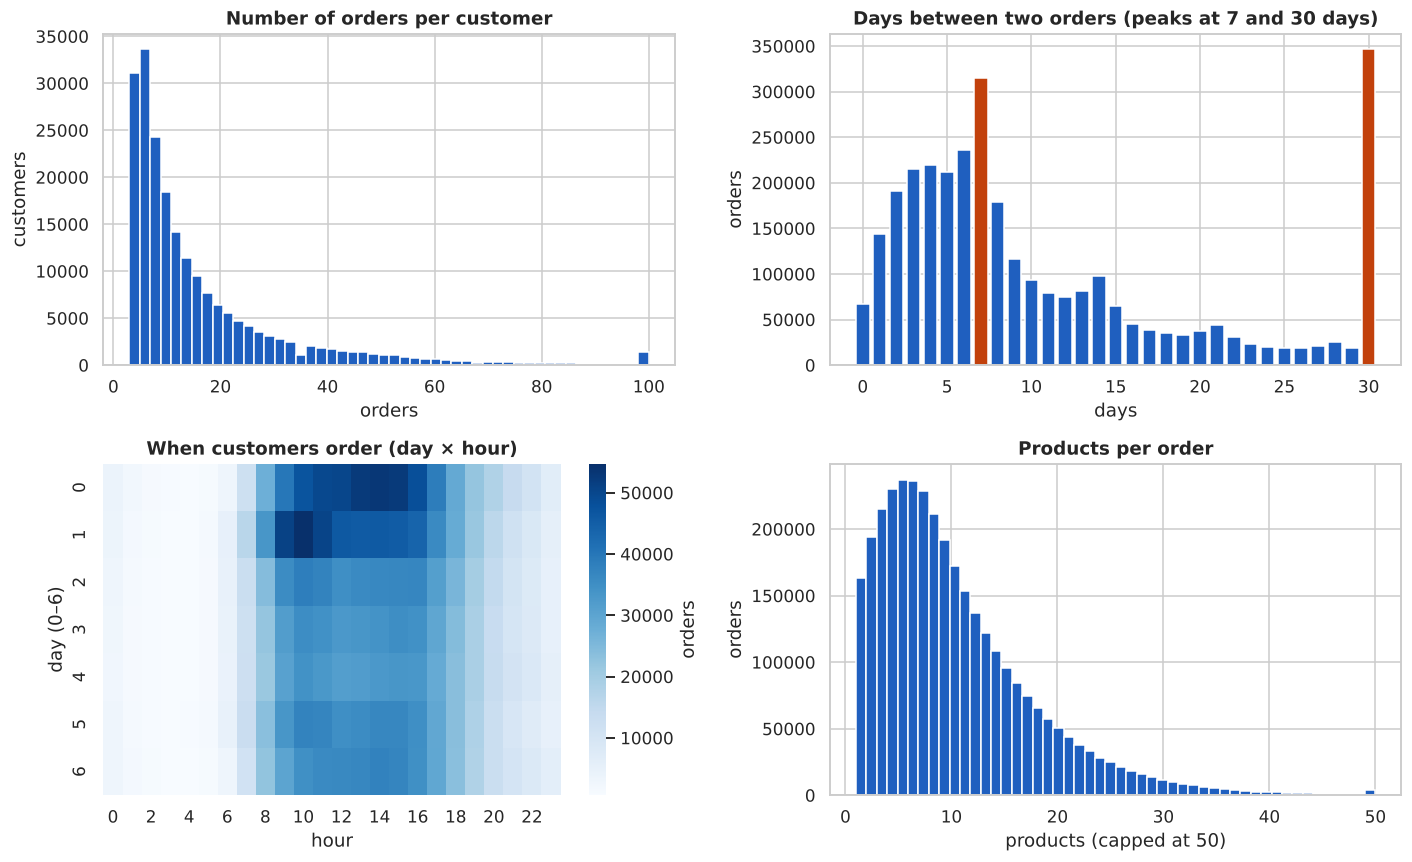

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]
ax.hist(per_user["n_orders"], bins=50, color=BLUE)
ax.set(title="Number of orders per customer", xlabel="orders", ylabel="customers")

ax = axes[0, 1]
vc = orders_ok["days_since_prior_order"].value_counts().sort_index()
ax.bar(vc.index, vc.values, color=[ORANGE if d in (7, 30) else BLUE for d in vc.index])
ax.set(title="Days between two orders (peaks at 7 and 30 days)", xlabel="days", ylabel="orders")

ax = axes[1, 0]
heat = orders_ok.pivot_table(index="order_dow", columns="order_hour_of_day", values="order_id", aggfunc="count")
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "orders"})
ax.set(title="When customers order (day × hour)", xlabel="hour", ylabel="day (0–6)")

ax = axes[1, 1]
ax.hist(basket.clip(upper=50), bins=50, color=BLUE)
ax.set(title="Products per order", xlabel="products (capped at 50)", ylabel="orders")
plt.tight_layout(); plt.show()

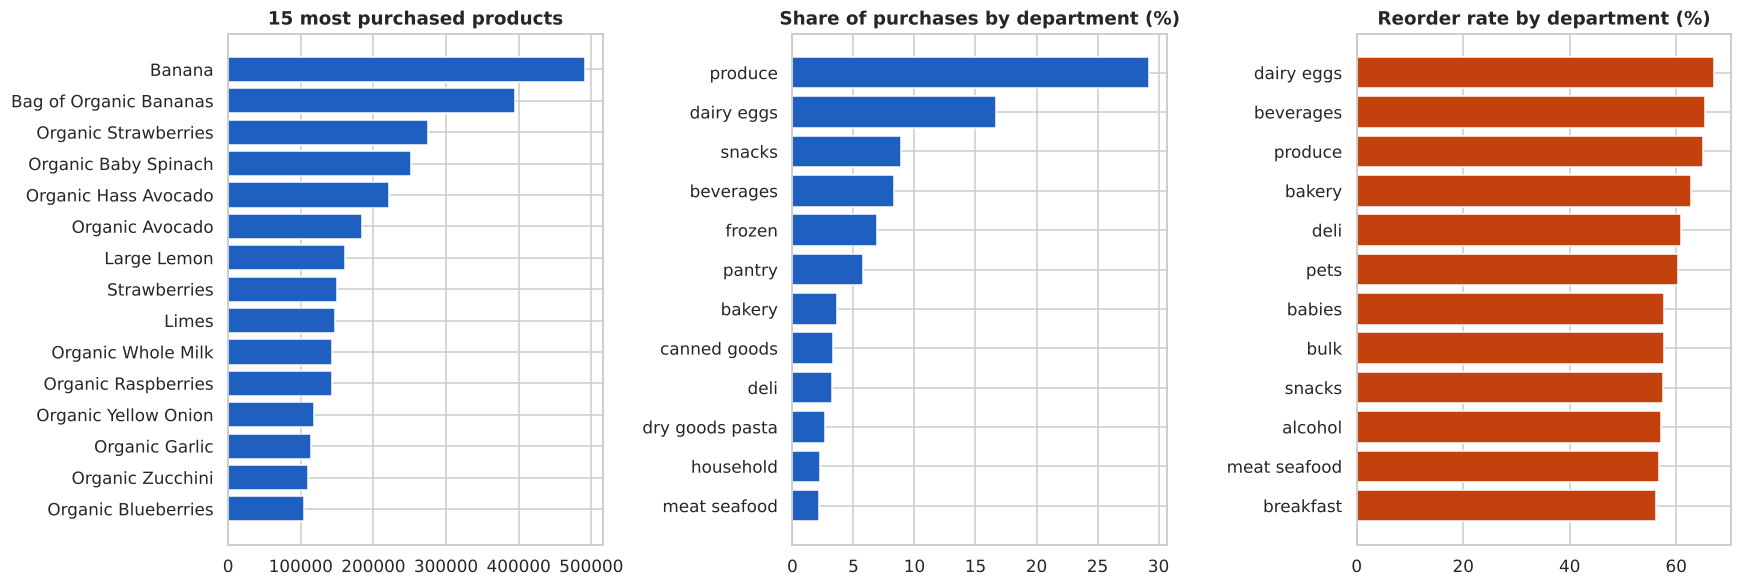

In [8]:
cat = products.merge(aisles, on="aisle_id").merge(departments, on="department_id")
names = cat.set_index("product_id")["product_name"]
dep_id = items["product_id"].map(cat.set_index("product_id")["department_id"]).astype("int8")
dep_name = departments.set_index("department_id")["department"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
top = items["product_id"].value_counts().head(15)[::-1]
axes[0].barh(top.index.map(names), top.values, color=BLUE); axes[0].set_title("15 most purchased products")
dep = dep_id.value_counts(normalize=True).head(12)[::-1] * 100
axes[1].barh(dep.index.map(dep_name), dep.values, color=BLUE); axes[1].set_title("Share of purchases by department (%)")
reo = items["reordered"].groupby(dep_id).mean().sort_values().tail(12) * 100
axes[2].barh(reo.index.map(dep_name), reo.values, color=ORANGE); axes[2].set_title("Reorder rate by department (%)")
plt.tight_layout(); plt.show()
del dep_id

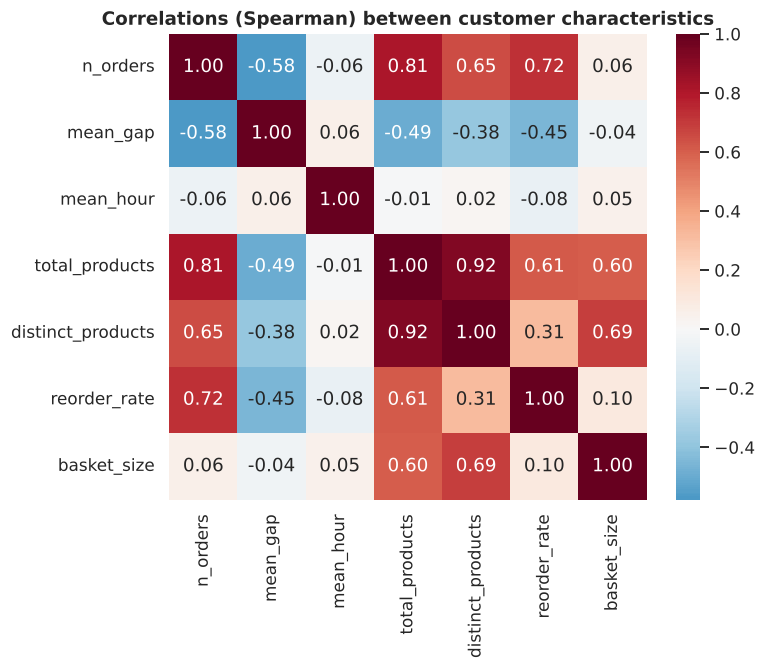

In [9]:
# Correlations between customer characteristics
u = orders_ok.groupby("user_id").agg(n_orders=("order_id", "size"),
                                     mean_gap=("days_since_prior_order", "mean"),
                                     mean_hour=("order_hour_of_day", "mean"))
uid = items["order_id"].map(orders_ok.set_index("order_id")["user_id"]).astype("int32")
ub = pd.DataFrame({"user_id": uid, "product_id": items["product_id"], "reordered": items["reordered"]}).groupby("user_id").agg(
    total_products=("product_id", "size"), distinct_products=("product_id", "nunique"),
    reorder_rate=("reordered", "mean"))
del uid
u = u.join(ub)
u["basket_size"] = u["total_products"] / u["n_orders"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(u.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlations (Spearman) between customer characteristics"); plt.show()

**Interpretation** *(written from the results above)*:

- **Customers:** 16 orders on average (median 10, from 3 to 100). Many occasional customers and a few very loyal ones (the peak at 100 is the cap set by Instacart).
- **Pace:** 11 days on average between two orders (median 7). Two peaks: **7 days** (weekly shopping) and **30 days**. The latter is an artefact: Instacart groups every gap of 30 days or more at 30 (10.3% of orders).
- **Timing:** orders mostly happen between 9 am and 5 pm, with a peak on days 0 and 1 (probably the weekend). This is the basis for choosing the send time (§14).
- **Basket:** 10 products on average (median 8).
- **Reorders:** 59% of purchased products are reorders. Repetition is the norm, which justifies SupplyMe.
- **Products:** produce (29% of purchases) and dairy & eggs (17%) dominate. They are also the most reordered departments (about 65%). Bananas are the number one product.
- **Correlations:** the more often a customer orders, the more they reorder the same products (ρ = 0.72) and the shorter the gap between their orders (ρ = −0.58). The ordering hour is linked to nothing (ρ ≈ 0): it is a personal habit, not a sign of loyalty.

## 4. Working sample and table merging

We work on the **3,000 real customers** of the group dataset, randomly drawn from Instacart's 206,209 customers (seed 20261118). The draw was done once for the whole group, so everyone works on the same customers.

We then **merge** the 6 tables into a single table: one row = one product in one order, with the customer, the date, the product and its department.

In [10]:
accounts = pd.read_excel(f"{BASE}/app/accounts.xlsx")
customers = np.sort(accounts.loc[accounts.origin == "observed_customer", "user_id"].astype(int).values)
N_CUSTOMERS = len(customers)
print(f"Real customers in the group dataset: {N_CUSTOMERS:,} · synthetic new accounts: {(accounts.origin == 'synthetic_new').sum():,}")

o = orders_ok[orders_ok.user_id.isin(customers)].sort_values(["user_id", "order_number"]).copy()
df = (items[items.order_id.isin(o.order_id)]
      .merge(o[["order_id", "user_id", "order_number", "order_dow", "order_hour_of_day", "days_since_prior_order"]], on="order_id")
      .merge(cat[["product_id", "product_name", "aisle", "department", "department_id"]], on="product_id"))
print(f"Merged table: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Missing values after merging (excluding days_since_prior_order):",
      int(df.drop(columns="days_since_prior_order").isna().sum().sum()))
display(df.head())

Real customers in the group dataset: 3,000 · synthetic new accounts: 1,000


Merged table: 493,119 rows × 13 columns
Missing values after merging (excluding days_since_prior_order): 0


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle,department,department_id
0,48,14129,1,0,172786,5,2,0,30.000,Organic Chicken Bone Broth,soup broth bouillon,canned goods,15
1,48,22298,2,1,172786,5,2,0,30.000,Yo Baby Organic Whole Milk Banana Mango Yogurt,yogurt,dairy eggs,16
2,48,17600,3,1,172786,5,2,0,30.000,"YoKids Squeezers Organic Low-Fat Yogurt, Straw...",yogurt,dairy eggs,16
3,48,6141,4,0,172786,5,2,0,30.000,Low Sodium Beef Broth,soup broth bouillon,canned goods,15
4,48,42169,5,0,172786,5,2,0,30.000,Organic Unrefined Toasted Sesame Oil,oils vinegars,pantry,13


## 5. Rebuilding the dates

Instacart gives **no dates**, only the gap with the previous order. We rebuild each customer's calendar:

1. `day` = cumulative sum of the gaps (1st order = day 0);
2. we align customers on the end of the history (`END_DATE`, 31 October 2026). Customers do not all order on the same day: each customer's last order is placed **between 0 and 13 days before** 31 October (random offset of about one ordering cycle, since the average gap is 11 days). This way, "today" falls at any point of each customer's cycle;
3. `date = END_DATE − (365 − day)`.

The **intervals are real**; only the absolute dates are a convention.

In [11]:
o["day"] = o["days_since_prior_order"].fillna(0).groupby(o["user_id"]).cumsum()
offset = pd.Series(np.random.default_rng(SEED + 2).integers(0, 14, N_CUSTOMERS), index=customers)
o["day"] = o["day"] - o.groupby("user_id")["day"].transform("max") + 365 - o["user_id"].map(offset)
o["date"] = END_DATE - pd.to_timedelta(365 - o["day"], unit="D")
df = df.merge(o[["order_id", "day", "date"]], on="order_id")

example = o[o.user_id == customers[0]][["order_number", "days_since_prior_order", "day", "date"]].head(8)
print(f"Example: customer {customers[0]}"); display(example)
print("Period covered:", o["date"].min().date(), "→", o["date"].max().date())

Example: customer 23


,order_number,days_since_prior_order,day,date
273,1,NaN,282.000,2026-08-09
274,2,9.000,291.000,2026-08-18
275,3,5.000,296.000,2026-08-23
276,4,30.000,326.000,2026-09-22
277,5,30.000,356.000,2026-10-22


Period covered: 2025-10-19 → 2026-10-31


## 6. Justified complementary data

Instacart contains no prices, no costs and no household size. Rather than using pure randomness, each value is **anchored on an official source**:

| Missing information | Method | Source |
|---|---|---|
| **Prices** | reference price per department, based on average U.S. prices collected by the government (eggs, milk, bread, bananas, beef, chicken, coffee, lettuce); realistic variation between products of the same department | U.S. Bureau of Labor Statistics, *Average Price Data* (U.S. city average, 2024–2026) |
| **Cost / margin** | average gross margin of grocery retail: 27.9% | NGA / FMS Solutions, *Independent Grocers Financial Survey* (fiscal year 2025); FMI: 30.5% in 2020 |
| **Household size** | official distribution of U.S. households (1 person 33%, 2 people 33%, 3 people 14%, 4 people 11%, 5+ 9%), assigned according to the **real basket size** (larger baskets → larger households) | U.S. EIA, *Residential Energy Consumption Survey* 2024, table HC9.4 |
| **Effect of a discount** | average price elasticity of −2.62 | Bijmolt, Van Heerde & Pieters (2005), *Journal of Marketing Research*, meta-analysis of 1,851 elasticities |
| **Quantities** | 1 unit per row (an Instacart row = one product present in the basket) | Instacart data structure |

Since the data are American, amounts are expressed in **U.S. dollars ($)**.

,BLS item,price_usd,period,Instacart department
0,"Eggs, grade A, large, per dozen",2.710,Sept 2025,dairy eggs
1,"Milk, whole, per gallon",4.050,Sept 2025,dairy eggs
2,"Bread, white, per lb",1.870,Sept 2025,bakery
3,"Bananas, per lb",0.650,Aug 2026,produce
4,"Lettuce, iceberg, per lb",1.470,Aug 2026,produce
5,"Ground beef, per lb",6.920,Aug 2026,meat seafood
6,"Chicken breast, per lb",4.170,Aug 2026,meat seafood
7,"Coffee, per lb",6.320,2024,beverages


Reference price for departments with no BLS item: $3.38 (median of the anchors)


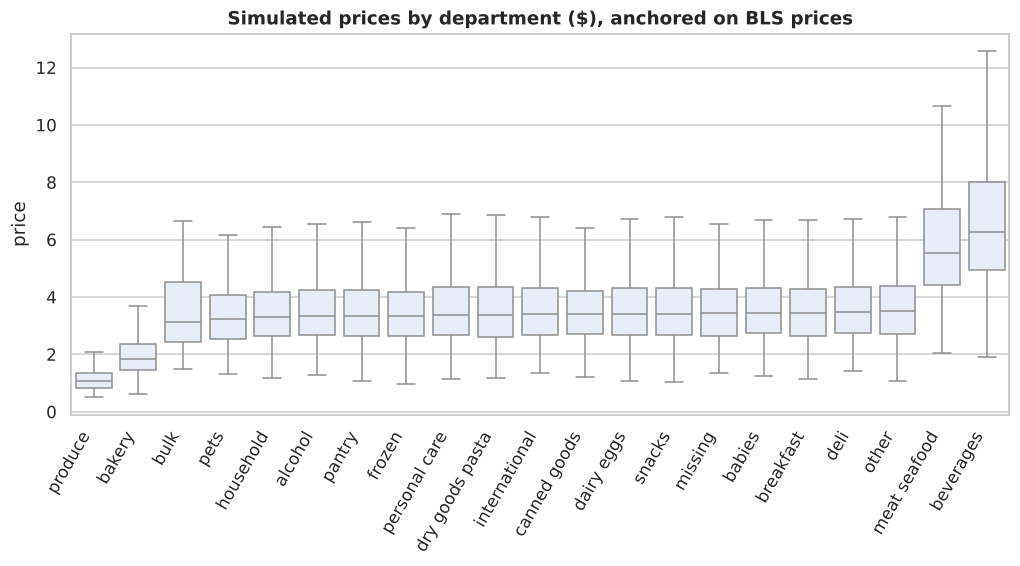

In [12]:
# Average prices collected by the BLS (U.S. city average), 1 unit of sale
BLS_ANCHORS = pd.DataFrame([
    ("Eggs, grade A, large, per dozen",  2.71, "Sept 2025", "dairy eggs"),
    ("Milk, whole, per gallon",          4.05, "Sept 2025", "dairy eggs"),
    ("Bread, white, per lb",             1.87, "Sept 2025", "bakery"),
    ("Bananas, per lb",                  0.65, "Aug 2026",  "produce"),
    ("Lettuce, iceberg, per lb",         1.47, "Aug 2026",  "produce"),
    ("Ground beef, per lb",              6.92, "Aug 2026",  "meat seafood"),
    ("Chicken breast, per lb",           4.17, "Aug 2026",  "meat seafood"),
    ("Coffee, per lb",                   6.32, "2024",      "beverages"),
], columns=["BLS item", "price_usd", "period", "Instacart department"])
display(BLS_ANCHORS)

dept_price = BLS_ANCHORS.groupby("Instacart department")["price_usd"].mean()
DEFAULT_PRICE = BLS_ANCHORS["price_usd"].median()   # departments with no BLS item: median of the anchors
print(f"Reference price for departments with no BLS item: ${DEFAULT_PRICE:.2f} (median of the anchors)")

GROSS_MARGIN = 0.279   # NGA / FMS Solutions 2025
cat_s = cat[cat.product_id.isin(df.product_id.unique())].copy()
rng = np.random.default_rng(SEED + 1)
ref = cat_s["department"].map(dept_price).fillna(DEFAULT_PRICE)
# variation between products of the same department (log-normal, standard deviation 0.35: assumption)
cat_s["price"] = (ref * rng.lognormal(0, 0.35, len(cat_s))).round(2).clip(lower=0.5)
cat_s["cost"] = (cat_s["price"] * (1 - GROSS_MARGIN)).round(2)
cat_s["margin"] = cat_s["price"] - cat_s["cost"]

plt.figure(figsize=(11, 4.5))
order = cat_s.groupby("department")["price"].median().sort_values().index
sns.boxplot(data=cat_s, x="department", y="price", order=order, color="#E3ECFA", showfliers=False)
plt.xticks(rotation=60, ha="right"); plt.title("Simulated prices by department ($), anchored on BLS prices"); plt.xlabel("")
plt.show()

In [13]:
# Household size: official distribution (EIA RECS 2024, millions of households)
RECS = pd.Series({1: 43.74, 2: 43.87, 3: 18.84, 4: 14.60, 5: 11.50})
share = RECS / RECS.sum()
basket_size = df.groupby(["user_id", "order_id"]).size().groupby("user_id").mean()
# customers are ranked by basket size, then split according to the official shares
rank = basket_size.rank(method="first", pct=True)
thresholds = share.cumsum().values
household = pd.Series(np.searchsorted(thresholds, rank.values, side="left") + 1, index=rank.index).clip(upper=5)
customers_df = pd.DataFrame({"household_size": household, "basket_size": basket_size})

comparison = pd.DataFrame({"EIA source (%)": (share * 100).round(1),
                           "sample (%)": (household.value_counts(normalize=True).sort_index() * 100).round(1),
                           "average basket (products)": customers_df.groupby("household_size")["basket_size"].mean().round(1)})
comparison.index.name = "people"
display(comparison)

,EIA source (%),sample (%),average basket (products)
people,,,
1,33.000,33.000,4.400
2,33.100,33.100,9.000
3,14.200,14.200,12.900
4,11.000,11.000,16.400
5,8.700,8.700,23.800


## 7. Part 1: analysing household purchase histories

,orders,total_spend,average_basket,days_between_orders,household_size
count,"3,000.000","3,000.000","3,000.000","3,000.000","3,000.000"
mean,16.100,514.200,31.900,15.400,2.300
std,16.600,657.700,20.200,7.100,1.300
min,3.000,5.900,1.500,0.300,1.000
25%,6.000,134.600,18.100,9.400,1.000
50%,10.000,283.900,28.000,14.900,2.000
75%,20.000,607.700,40.900,20.500,3.000
max,100.000,"6,931.800",207.500,30.000,5.000


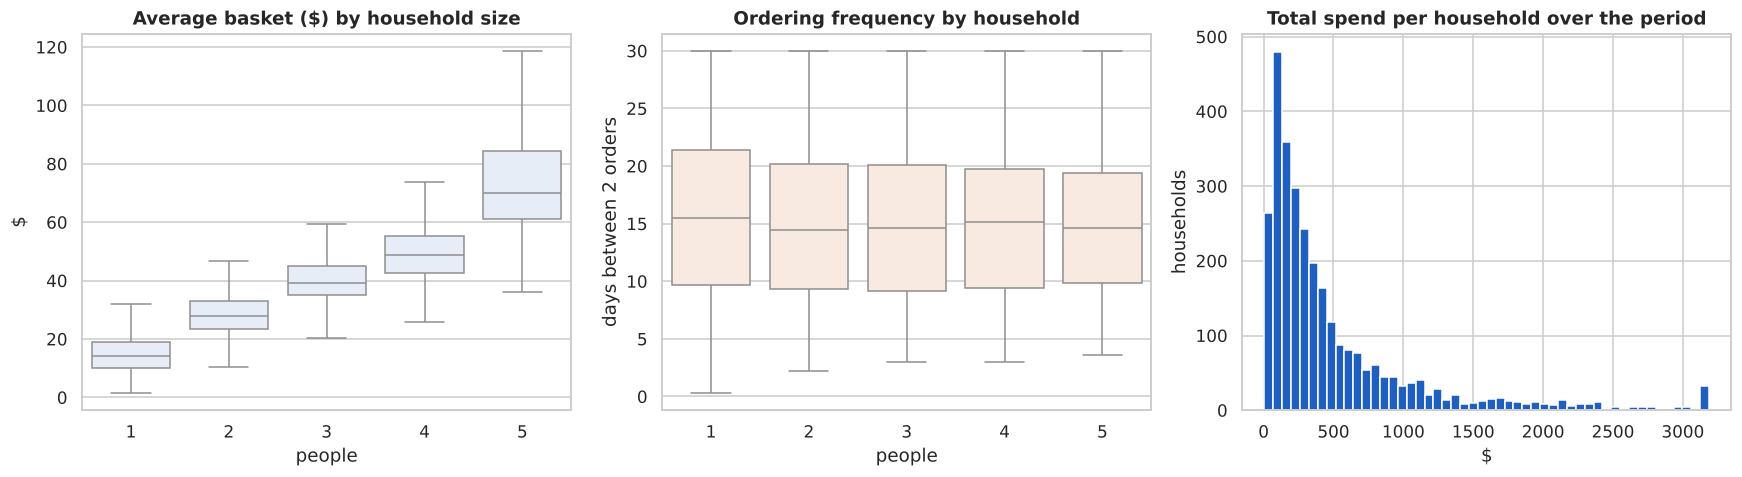

In [14]:
df = df.merge(cat_s[["product_id", "price", "cost", "margin"]], on="product_id")
order_totals = df.groupby(["user_id", "order_id"]).agg(amount=("price", "sum"), products=("product_id", "size")).reset_index()
hist = order_totals.groupby("user_id").agg(orders=("order_id", "size"), total_spend=("amount", "sum"),
                                           average_basket=("amount", "mean"))
hist = hist.join(o.groupby("user_id")["days_since_prior_order"].mean().rename("days_between_orders"))
hist = hist.join(customers_df["household_size"])
display(hist.describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=hist, x="household_size", y="average_basket", ax=axes[0], color="#E3ECFA", showfliers=False)
axes[0].set(title="Average basket ($) by household size", xlabel="people", ylabel="$")
sns.boxplot(data=hist, x="household_size", y="days_between_orders", ax=axes[1], color="#FCE9DC", showfliers=False)
axes[1].set(title="Ordering frequency by household", xlabel="people", ylabel="days between 2 orders")
axes[2].hist(hist["total_spend"].clip(upper=hist["total_spend"].quantile(0.99)), bins=50, color=BLUE)
axes[2].set(title="Total spend per household over the period", xlabel="$", ylabel="households")
plt.tight_layout(); plt.show()

## 8. Part 2: identifying consumption habits

For each **customer × product** pair, we compute the **interval between two purchases** of the same product. A product bought at regular intervals is a **habit**: this is exactly what SupplyMe tries to anticipate.

**Regularity** is measured by the coefficient of variation (CV = standard deviation ÷ mean of the intervals): the lower it is, the more regular the habit.

Customer × product pairs bought at least 3 times: 47,569


,% of habits
profile,
regular,48.800
very regular,31.100
irregular,20.100


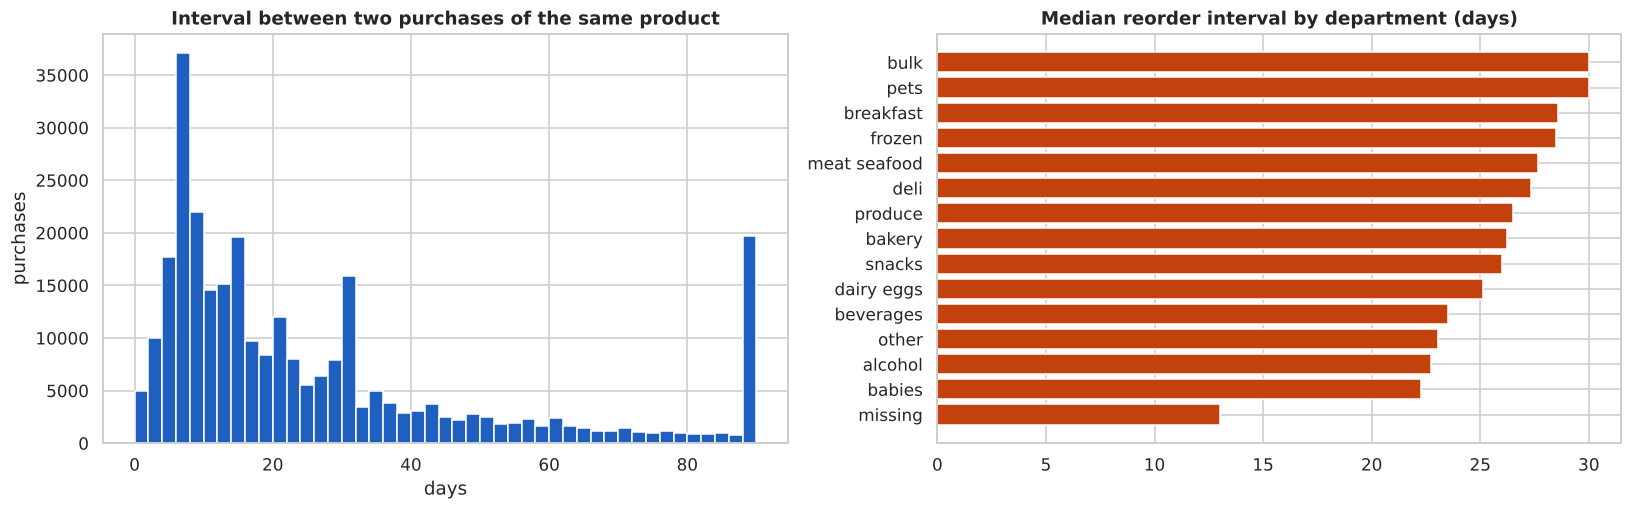

Example: the habits of customer 97899


,product,department,purchases,mean_interval,cv,profile
96916,Banana,produce,33,7.220,0.580,regular
96906,2% Reduced Fat Milk,dairy eggs,33,8.190,0.610,regular
96642,Mixed Bell Peppers,produce,32,8.450,0.610,regular
96627,English Muffins,bakery,30,7.970,0.440,very regular
96660,Cinnamon Swirl Raisin Bread,bakery,30,7.970,0.340,very regular
97057,Apple Juice,beverages,30,9.000,0.630,regular
97115,Split Top White Bread,bakery,28,8.300,0.390,very regular
96739,Diet Coke Caffeine Free Soda,beverages,26,7.560,0.380,very regular
96728,Broccoli Crown,produce,25,9.330,0.670,regular
97156,Activia Peach/Strawberry Lowfat Yogurt,dairy eggs,23,9.860,0.580,regular


In [15]:
ev = df[["user_id", "product_id", "order_number", "day", "add_to_cart_order", "reordered", "department_id", "department", "product_name"]] \
    .sort_values(["user_id", "product_id", "day"]).reset_index(drop=True)
ev["interval"] = ev.groupby(["user_id", "product_id"])["day"].diff()

habits = ev.groupby(["user_id", "product_id"]).agg(purchases=("day", "size"), mean_interval=("interval", "mean"),
                                                   interval_sd=("interval", "std"), department=("department", "first"),
                                                   product=("product_name", "first")).reset_index()
habits = habits[habits.purchases >= 3].copy()
habits["cv"] = habits["interval_sd"] / habits["mean_interval"].clip(lower=1)
habits["profile"] = pd.cut(habits["cv"], [-0.01, 0.5, 1.0, np.inf], labels=["very regular", "regular", "irregular"])
print(f"Customer × product pairs bought at least 3 times: {len(habits):,}")
display(habits["profile"].value_counts(normalize=True).mul(100).round(1).to_frame("% of habits"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].hist(ev["interval"].dropna().clip(upper=90), bins=45, color=BLUE)
axes[0].set(title="Interval between two purchases of the same product", xlabel="days", ylabel="purchases")
med = habits.groupby("department")["mean_interval"].median().sort_values().head(15)
axes[1].barh(med.index, med.values, color=ORANGE)
axes[1].set(title="Median reorder interval by department (days)")
plt.tight_layout(); plt.show()

customer_ex = habits.groupby("user_id").size().idxmax()
print(f"Example: the habits of customer {customer_ex}")
display(habits[habits.user_id == customer_ex].sort_values("purchases", ascending=False)
        [["product", "department", "purchases", "mean_interval", "cv", "profile"]].head(10).round(2))

## 9. Explanatory variables and train / test split

### The principle: snapshots in time
We place ourselves at a past date *s* (a "snapshot"). The variables are computed **only from purchases made before *s***; the outcome to predict is what happens **after *s***.

Two targets:
- **regression:** `days_to_next_purchase` of the product;
- **classification:** `buy_within_7d` = 1 if the product is bought again within 7 days (useful to decide whether to send a reminder).

### Why a **time-based** split rather than a random one?
A random split would mix past and future: the model would "see the future" and its scores would look falsely good (**data leakage**). Here:
- **train:** 12 snapshots, from January to June;
- **60-day gap** (training outcomes never overlap with the test period);
- **test:** 3 snapshots, in August and September, never seen during training.

### Censoring
If the product is not bought again within 60 days, the delay is unknown: the observation is excluded from the regression but kept for the classification (outcome = 0).

In [16]:
H, W = 60, 7   # observation horizon (days) and classification window

def build_features(s, with_target=True, min_purchases=2, max_purchases=None):
    h, oh = ev[ev.day <= s], o[o.day <= s]
    key = ["user_id", "product_id"]
    g = h.groupby(key)
    f = g.agg(n_purchases=("day", "size"), first=("day", "min"), last=("day", "max"),
              mean_interval=("interval", "mean"), median_interval=("interval", "median"),
              interval_sd=("interval", "std"), last_interval=("interval", "last"),
              cart_position=("add_to_cart_order", "mean"), last_order_num=("order_number", "max"),
              first_order_num=("order_number", "min"), department=("department_id", "first")).reset_index()
    f = f[(f.n_purchases >= min_purchases) & (f.n_purchases <= (max_purchases or np.inf))]
    uc = oh.groupby("user_id").agg(c_orders=("order_id", "size"), c_mean_gap=("days_since_prior_order", "mean"),
                                   c_gap_sd=("days_since_prior_order", "std"), c_last_day=("day", "max"),
                                   c_order_num=("order_number", "max")).reset_index()
    ua = h.groupby("user_id").agg(c_lines=("product_id", "size"), c_distinct_products=("product_id", "nunique"),
                                  c_reorder_rate=("reordered", "mean")).reset_index()
    uc = uc.merge(ua, on="user_id")
    uc["c_basket_size"] = uc["c_lines"] / uc["c_orders"]
    f = f.merge(uc, on="user_id")
    rec = h[h.order_number > h.user_id.map(uc.set_index("user_id")["c_order_num"]) - 5].groupby(key).size().rename("share_last_5")
    f = f.merge(rec, left_on=key, right_index=True, how="left")
    f["share_last_5"] = f["share_last_5"].fillna(0) / 5
    f["days_since_purchase"] = s - f["last"]
    f["c_days_since_order"] = s - f["c_last_day"]
    f["overdue_index"] = f["days_since_purchase"] / f["mean_interval"].clip(lower=1)
    f["c_overdue_index"] = f["c_days_since_order"] / f["c_mean_gap"].clip(lower=1)
    f["orders_since_purchase"] = f["c_order_num"] - f["last_order_num"]
    f["presence_rate"] = f["n_purchases"] / (f["c_order_num"] - f["first_order_num"] + 1)
    f["monthly_frequency"] = (f["n_purchases"] - 1) / (f["last"] - f["first"]).clip(lower=1) * 30
    p = h.groupby("product_id").agg(p_reorder_rate=("reordered", "mean"), p_buyers=("user_id", "nunique"),
                                    p_median_interval=("interval", "median")).reset_index()
    f = f.merge(p, on="product_id", how="left").merge(customers_df[["household_size"]], left_on="user_id", right_index=True)
    f["snapshot"] = s
    if with_target:
        future = ev[ev.day > s].groupby(key)["day"].min().rename("next")
        f = f.merge(future, left_on=key, right_index=True, how="left")
        d = f["next"] - s
        f["days_to_next_purchase"] = d
        f["censored"] = d.isna() | (d > H)
        f["buy_within_7d"] = (d <= W).fillna(False).astype(int)
    return f

FEATURES = ["days_since_purchase", "mean_interval", "median_interval", "interval_sd", "last_interval",
            "overdue_index", "n_purchases", "monthly_frequency", "presence_rate", "share_last_5", "orders_since_purchase",
            "cart_position", "c_orders", "c_mean_gap", "c_gap_sd", "c_days_since_order", "c_overdue_index",
            "c_distinct_products", "c_reorder_rate", "c_basket_size", "household_size",
            "p_reorder_rate", "p_buyers", "p_median_interval", "department"]

snap_test = [365 - H - 14 * i for i in range(3)][::-1]
snap_train = [snap_test[0] - H - 14 * i for i in range(12)][::-1]
t0 = time.time()
TR = pd.concat([build_features(s) for s in snap_train], ignore_index=True)
TE = pd.concat([build_features(s) for s in snap_test], ignore_index=True)
for d_ in (TR, TE):
    d_[FEATURES] = d_[FEATURES].astype(float).fillna(-1)
print(f"Features built in {time.time()-t0:.0f} s")
print(f"Train: {len(TR):,} observations ({len(snap_train)} snapshots) | Test: {len(TE):,} ({len(snap_test)} snapshots)")
print(f"Censored share (no repurchase within {H} days) — train: {TR.censored.mean():.1%} · test: {TE.censored.mean():.1%}")
print(f"Share of purchases within 7 days — train: {TR.buy_within_7d.mean():.1%} · test: {TE.buy_within_7d.mean():.1%}")

Features built in 2 s
Train: 214,685 observations (12 snapshots) | Test: 153,099 (3 snapshots)
Censored share (no repurchase within 60 days) — train: 46.8% · test: 56.9%
Share of purchases within 7 days — train: 16.4% · test: 11.7%


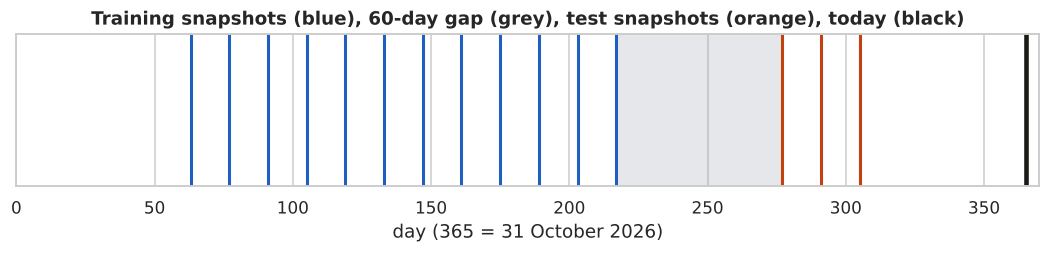

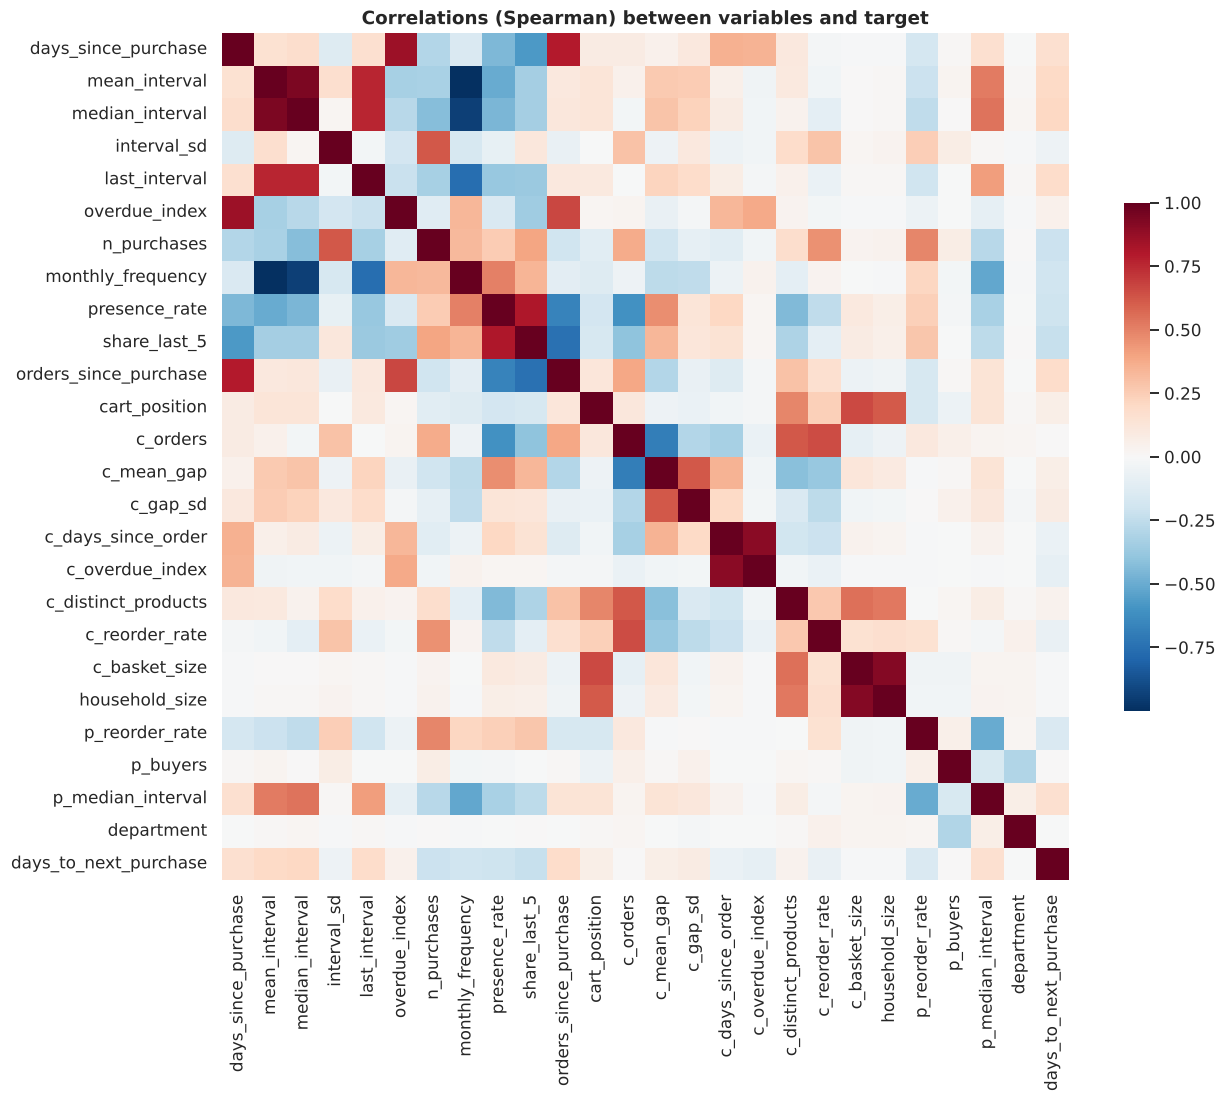

Variables most correlated with the time until the next purchase:


,rho
share_last_5,-0.231
n_purchases,-0.213
median_interval,0.207
presence_rate,-0.205
mean_interval,0.198
monthly_frequency,-0.198
last_interval,0.180
orders_since_purchase,0.180


In [17]:
# Timeline of the time-based split
fig, ax = plt.subplots(figsize=(12, 1.8))
for s in snap_train: ax.axvline(s, color=BLUE, lw=2)
for s in snap_test: ax.axvline(s, color=ORANGE, lw=2)
ax.axvspan(max(snap_train), min(snap_test), color=GREY, alpha=0.25)
ax.axvline(365, color=DARK, lw=3)
ax.set_xlim(0, 370); ax.set_yticks([]); ax.set_xlabel("day (365 = 31 October 2026)")
ax.set_title("Training snapshots (blue), 60-day gap (grey), test snapshots (orange), today (black)")
plt.show()

corr = TR.loc[~TR.censored, FEATURES + ["days_to_next_purchase"]].sample(100_000, random_state=SEED).corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Correlations (Spearman) between variables and target"); plt.show()
print("Variables most correlated with the time until the next purchase:")
display(corr["days_to_next_purchase"].drop("days_to_next_purchase").sort_values(key=abs, ascending=False).head(8).round(3).to_frame("rho"))

## 10. Part 3a: predicting the time until the next purchase (regression)

Five approaches compared on the **same test period**:

| Model | Idea |
|---|---|
| **Baseline** | common-sense rule: usual median interval − days elapsed |
| **Linear regression** | straight-line relationship between the variables and the delay |
| **Random Forest** | average of many decision trees |
| **XGBoost** | trees built one after another, each one correcting the errors of the previous ones (*boosting*) |
| **LightGBM** | same principle as XGBoost, faster on large volumes |

Metrics: **MAE** (mean error in days), **RMSE** (penalises large errors), **R²** (share of variance explained), **% within ±7 days**.

In [18]:
tr_r, te_r = TR[~TR.censored], TE[~TE.censored]
Xtr, ytr = tr_r[FEATURES], tr_r["days_to_next_purchase"]
Xte, yte = te_r[FEATURES], te_r["days_to_next_purchase"]
sub = Xtr.sample(min(200_000, len(Xtr)), random_state=SEED).index   # sub-sample for the slow models

def reg_scores(y, p):
    return {"MAE (d)": mean_absolute_error(y, p), "RMSE (d)": np.sqrt(mean_squared_error(y, p)),
            "R²": r2_score(y, p), "% within ±7 d": np.mean(np.abs(y - p) <= 7) * 100}

reg_models = {
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8,
                                objective="reg:absoluteerror", tree_method="hist", n_jobs=-1, random_state=SEED),
    "LightGBM": lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, objective="l1", verbose=-1, random_state=SEED),
}
res_reg, preds_reg = {}, {}
preds_reg["Baseline"] = np.clip(te_r["median_interval"] - te_r["days_since_purchase"], 1, H)
res_reg["Baseline"] = reg_scores(yte, preds_reg["Baseline"])
for name, m in reg_models.items():
    t0 = time.time()
    slow = name in ("Random Forest",)
    m.fit(Xtr.loc[sub] if slow else Xtr, ytr.loc[sub] if slow else ytr)
    preds_reg[name] = np.clip(m.predict(Xte), 1, H)
    res_reg[name] = reg_scores(yte, preds_reg[name])
    print(f"{name:<20} trained in {time.time()-t0:5.1f} s")

tab_reg = pd.DataFrame(res_reg).T.sort_values("MAE (d)")
tab_reg["MAE gain vs baseline (%)"] = (1 - tab_reg["MAE (d)"] / tab_reg.loc["Baseline", "MAE (d)"]) * 100
display(tab_reg.round(2))

Linear regression    trained in   0.1 s


Random Forest        trained in  39.9 s


XGBoost              trained in   5.2 s


LightGBM             trained in   6.0 s


,MAE (d),RMSE (d),R²,% within ±7 d,MAE gain vs baseline (%)
LightGBM,12.110,15.700,0.030,38.750,30.610
Random Forest,12.190,15.050,0.110,33.550,30.170
Linear regression,12.250,15.140,0.100,33.170,29.820
XGBoost,12.250,15.540,0.050,36.180,29.800
Baseline,17.450,23.430,-1.160,35.670,0.000


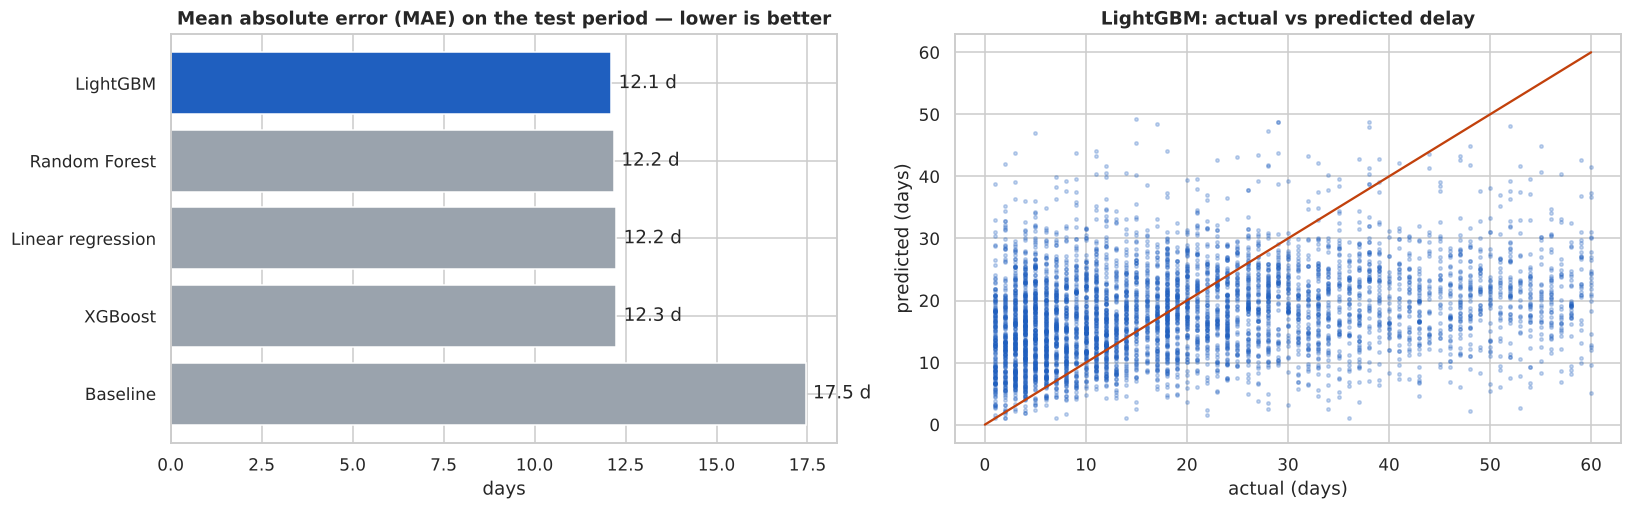

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
t = tab_reg.sort_values("MAE (d)", ascending=False)
axes[0].barh(t.index, t["MAE (d)"], color=[BLUE if i == t["MAE (d)"].idxmin() else GREY for i in t.index])
for i, v in enumerate(t["MAE (d)"]): axes[0].text(v + 0.2, i, f"{v:.1f} d", va="center")
axes[0].set(title="Mean absolute error (MAE) on the test period — lower is better", xlabel="days")
best_reg = tab_reg["MAE (d)"].idxmin()
plot_idx = np.random.default_rng(0).choice(len(yte), 5000, replace=False)
axes[1].scatter(yte.values[plot_idx], preds_reg[best_reg][plot_idx], s=5, alpha=0.25, color=BLUE)
axes[1].plot([0, H], [0, H], color=ORANGE)
axes[1].set(title=f"{best_reg}: actual vs predicted delay", xlabel="actual (days)", ylabel="predicted (days)")
plt.tight_layout(); plt.show()

## 11. Part 3b: probability of repurchase within 7 days (classification)

This probability is what the marketing engine uses. Metrics:
- **AUC:** probability that the model ranks a buyer above a non-buyer (0.5 = chance, 1 = perfect);
- **Average Precision:** quality of the ranking of buyers (to be compared with the base rate);
- **Brier score:** error of the probabilities (lower = better calibrated).

Logistic regression    trained in   0.5 s


Random Forest          trained in  78.3 s


XGBoost                trained in   7.5 s


LightGBM               trained in  14.7 s


Base rate (purchases within 7 days in the test set): 11.7%


,AUC,Average Precision,Brier
Random Forest,0.796,0.398,0.087
Logistic regression,0.789,0.372,0.088
LightGBM,0.779,0.371,0.089
XGBoost,0.777,0.368,0.089
Baseline,0.739,0.254,NaN


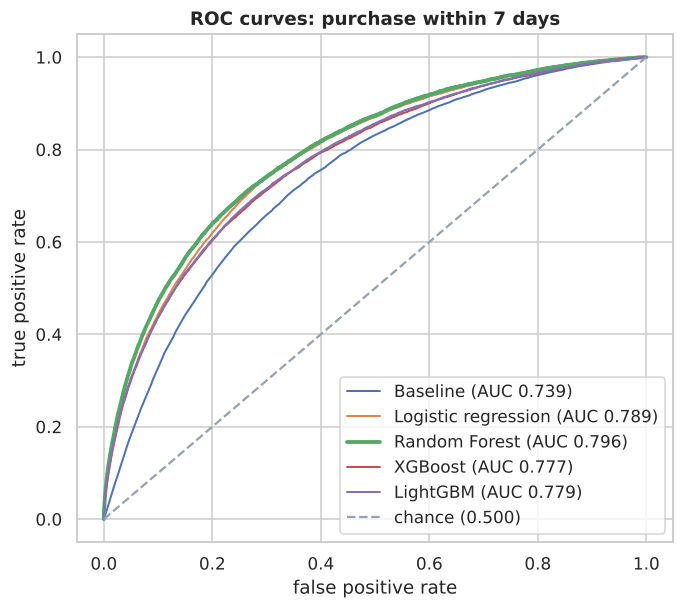

In [20]:
Xtr_c, ytr_c = TR[FEATURES], TR["buy_within_7d"]
Xte_c, yte_c = TE[FEATURES], TE["buy_within_7d"]
sub_c = Xtr_c.sample(min(200_000, len(Xtr_c)), random_state=SEED).index

cls_models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED),
    "XGBoost": xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                 tree_method="hist", eval_metric="auc", n_jobs=-1, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=63, min_child_samples=50, subsample=0.8,
                                   subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=SEED),
}
res_cls, probas = {}, {}
# baseline: the more "due" the product is compared with its usual pace, the more likely the purchase
probas["Baseline"] = -np.abs(TE["median_interval"] - TE["days_since_purchase"] - 3.5)
for name, m in cls_models.items():
    t0 = time.time()
    slow = name == "Random Forest"
    m.fit(Xtr_c.loc[sub_c] if slow else Xtr_c, ytr_c.loc[sub_c] if slow else ytr_c)
    probas[name] = m.predict_proba(Xte_c)[:, 1]
    print(f"{name:<22} trained in {time.time()-t0:5.1f} s")
for name, p in probas.items():
    res_cls[name] = {"AUC": roc_auc_score(yte_c, p), "Average Precision": average_precision_score(yte_c, p),
                     "Brier": brier_score_loss(yte_c, p) if name != "Baseline" else np.nan}
tab_cls = pd.DataFrame(res_cls).T.sort_values("AUC", ascending=False)
print(f"Base rate (purchases within 7 days in the test set): {yte_c.mean():.1%}")
display(tab_cls.round(3))

plt.figure(figsize=(7, 6))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(yte_c, p)
    plt.plot(fpr, tpr, lw=2.5 if name == tab_cls.index[0] else 1.3, label=f"{name} (AUC {res_cls[name]['AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color=GREY, label="chance (0.500)")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.title("ROC curves: purchase within 7 days"); plt.legend(loc="lower right"); plt.show()

## 12. Model selection on a validation period

The test set must be used only once. To **choose** the model, we create a **validation** period inside the training data: the models are trained on the first snapshots and compared on the **last 3 training snapshots** (with the same 60-day gap). We compare the 4 models and several LightGBM settings. The winner is then retrained on the whole training set and evaluated only once on the test set.

In [21]:
val_snaps = snap_train[-3:]
Fit, Val = TR[TR.snapshot <= val_snaps[0] - H], TR[TR.snapshot.isin(val_snaps)]
sub_v = Fit.sample(min(200_000, len(Fit)), random_state=SEED).index
grid = {
    "LightGBM (31 leaves)": dict(num_leaves=31, learning_rate=0.05, n_estimators=600, min_child_samples=50),
    "LightGBM (63 leaves, slow)": dict(num_leaves=63, learning_rate=0.02, n_estimators=1200, min_child_samples=200),
    "LightGBM (15 leaves, regularised)": dict(num_leaves=15, learning_rate=0.03, n_estimators=600, min_child_samples=300),
}
candidates = {name: m for name, m in cls_models.items()}
candidates.update({name: lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1,
                                            random_state=SEED, **p) for name, p in grid.items()})
val_auc = {}
for name, m in candidates.items():
    m = clone(m)
    slow = name == "Random Forest"
    m.fit(Fit.loc[sub_v, FEATURES] if slow else Fit[FEATURES], Fit.loc[sub_v, "buy_within_7d"] if slow else Fit["buy_within_7d"])
    val_auc[name] = roc_auc_score(Val.buy_within_7d, m.predict_proba(Val[FEATURES])[:, 1])
    print(f"{name:<36} validation AUC = {val_auc[name]:.4f}")
val_auc = pd.Series(val_auc, name="validation AUC").sort_values(ascending=False)
BEST_CLS = val_auc.index[0]
print(f"\nModel selected on the validation period: {BEST_CLS}")

clf_final = clone(candidates[BEST_CLS])
clf_final.fit(Xtr_c.loc[sub_c] if BEST_CLS == "Random Forest" else Xtr_c, ytr_c.loc[sub_c] if BEST_CLS == "Random Forest" else ytr_c)
p_final = clf_final.predict_proba(Xte_c)[:, 1]
print(f"{BEST_CLS}: test AUC = {roc_auc_score(yte_c, p_final):.4f} · "
      f"Average Precision = {average_precision_score(yte_c, p_final):.3f} · Brier = {brier_score_loss(yte_c, p_final):.4f}")
reg_final = reg_models[best_reg] if best_reg != "Baseline" else reg_models["LightGBM"]

Logistic regression                  validation AUC = 0.7674


Random Forest                        validation AUC = 0.7586


XGBoost                              validation AUC = 0.7360


LightGBM                             validation AUC = 0.7413


LightGBM (31 leaves)                 validation AUC = 0.7401


LightGBM (63 leaves, slow)           validation AUC = 0.7402


LightGBM (15 leaves, regularised)    validation AUC = 0.7569

Model selected on the validation period: Logistic regression


Logistic regression: test AUC = 0.7889 · Average Precision = 0.372 · Brier = 0.0885


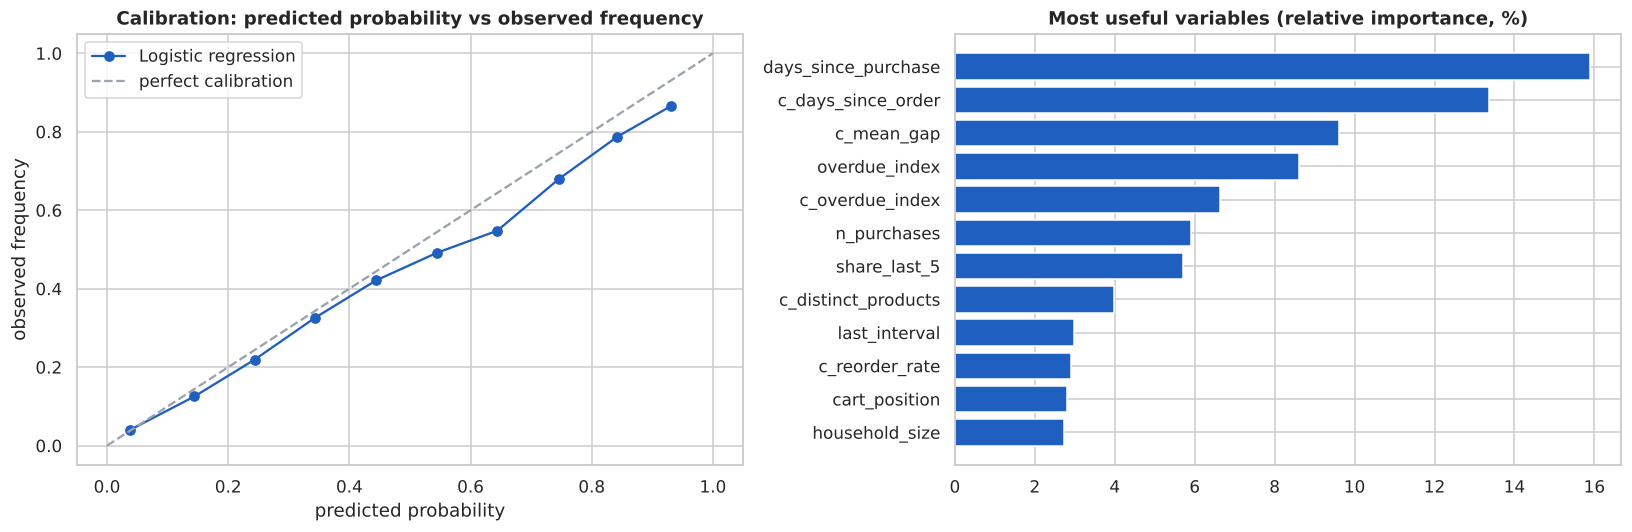

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
frac, mean_p = calibration_curve(yte_c, p_final, n_bins=10)
axes[0].plot(mean_p, frac, "o-", color=BLUE, label=BEST_CLS)
axes[0].plot([0, 1], [0, 1], "--", color=GREY, label="perfect calibration")
axes[0].set(title="Calibration: predicted probability vs observed frequency", xlabel="predicted probability", ylabel="observed frequency")
axes[0].legend()
model_ = clf_final[-1] if hasattr(clf_final, "steps") else clf_final
weights = model_.feature_importances_ if hasattr(model_, "feature_importances_") else np.abs(model_.coef_[0])
imp = pd.Series(weights, index=FEATURES).sort_values()
imp = imp / imp.sum() * 100
axes[1].barh(imp.index[-12:], imp.values[-12:], color=BLUE)
axes[1].set(title="Most useful variables (relative importance, %)")
plt.tight_layout(); plt.show()

### Why doesn't the AUC reach 0.95?

- **The selected model, logistic regression, reaches an AUC of 0.789 on the test set:** 8 times out of 10, a buyer is ranked above a non-buyer. Its *average precision* (0.37) is **3.2 times** the base rate (11.7%), while the simple rule only reaches 0.739.
- **Why does a simple model win?** With 3,000 customers, complex models (LightGBM, XGBoost) also learn the "noise" of the training period. On the validation period, logistic regression does better (0.767) than LightGBM (0.740 to 0.757). Random Forest is slightly better on the test set (0.796), but a model is **never** chosen by looking at the test set: the test would then be used twice, once to choose and once to evaluate, and the reported performance would be biased upward.
- **A natural ceiling:** whether a product will be bought again within 7 days depends on things we cannot see (what is left in the cupboard, unexpected events, in-store purchases). All models lie between 0.777 and 0.796: the limit comes from the available information, not from the choice of model.
- **An AUC of 0.95 would be suspicious:** it would almost always signal data leakage. Our time-based split prevents it.
- **For the delay,** LightGBM is the best: 12.1 days of error versus 17.5 for the simple rule (−31%). The R² is low because the exact timing of an individual purchase is very noisy; what matters for the decision is to correctly **rank** who is going to buy soon.

## 12 bis. What about new customers with no history? (cold start)

The main model relies on the customer's **personal** habits (their intervals between purchases). What can we do for a customer who has just arrived? Three situations:

| Situation | What we know | SupplyMe's answer |
|---|---|---|
| **0 orders** | nothing about the customer | no individual prediction: **welcome basket** (most purchased and reordered products), possibly with a short questionnaire (household size); goal: obtain the 1st order |
| **1 purchase of a product** | the date of that purchase, but no personal pace yet | **cold-start model:** we predict using the experience of **other customers** (median interval of the product, reorder rate) and the customer's ordering pace |
| **2 purchases or more** | a personal pace | **main model**, whose accuracy increases with the history |

We check each answer on the data.

In [23]:
# 0 orders vs 1 order: what share of the 2nd basket can we guess?
p1 = df[df.order_number == 1].groupby("user_id")["product_id"].apply(set)
p2 = df[df.order_number == 2].groupby("user_id")["product_id"].apply(set)
uu = p1.index.intersection(p2.index)
top10 = set(df.groupby("product_id")["user_id"].nunique().nlargest(10).index)
coverage = pd.DataFrame({"share of the 2nd basket recovered": [
    np.mean([len(top10 & p2[i]) / len(p2[i]) for i in uu]),
    np.mean([len(p1[i] & p2[i]) / len(p2[i]) for i in uu])]},
    index=["0 orders: the 10 best-sellers", "1 order: the customer's 1st basket"])
display((coverage * 100).round(1).rename(columns=lambda c: c + " (%)"))

,share of the 2nd basket recovered (%)
0 orders: the 10 best-sellers,7.000
1 order: the customer's 1st basket,29.300


In [24]:
# 1 purchase: the cold-start model, trained and tested on products bought only once
COLD_FEATURES = [v for v in FEATURES if v not in ("mean_interval", "median_interval", "interval_sd",
                 "last_interval", "overdue_index", "n_purchases", "monthly_frequency")] + ["delay_vs_product"]
def cold_set(snaps):
    d_ = pd.concat([build_features(s, min_purchases=1, max_purchases=1) for s in snaps], ignore_index=True)
    d_["delay_vs_product"] = d_["days_since_purchase"] / d_["p_median_interval"].clip(lower=1)
    d_[COLD_FEATURES] = d_[COLD_FEATURES].astype(float).fillna(-1)
    return d_
TRf, TEf = cold_set(snap_train), cold_set(snap_test)
print(f"Products bought only once — train: {len(TRf):,} · test: {len(TEf):,} · repurchase within 7 days: {TEf.buy_within_7d.mean():.1%}")

rule = -np.abs(TEf["p_median_interval"] - TEf["days_since_purchase"] - 3.5)
cold = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=SEED).fit(TRf[COLD_FEATURES], TRf.buy_within_7d)
p_cold = cold.predict_proba(TEf[COLD_FEATURES])[:, 1]
nc_tr, nc_te = TRf[~TRf.censored], TEf[~TEf.censored]
reg_cold = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, objective="l1", verbose=-1,
                             random_state=SEED).fit(nc_tr[COLD_FEATURES], nc_tr.days_to_next_purchase)
tab_cold = pd.DataFrame({
    "AUC": [roc_auc_score(TEf.buy_within_7d, rule), roc_auc_score(TEf.buy_within_7d, p_cold)],
    "delay MAE (d)": [mean_absolute_error(nc_te.days_to_next_purchase, np.clip(nc_te.p_median_interval - nc_te.days_since_purchase, 1, H)),
                      mean_absolute_error(nc_te.days_to_next_purchase, np.clip(reg_cold.predict(nc_te[COLD_FEATURES]), 1, H))]},
    index=["Rule: other customers' pace", "Cold-start model (LightGBM)"])
display(tab_cold.round(3))

Products bought only once — train: 327,865 · test: 235,052 · repurchase within 7 days: 2.9%


,AUC,delay MAE (d)
Rule: other customers' pace,0.697,22.166
Cold-start model (LightGBM),0.742,13.921


,observations,AUC
history,,
1–3,"5,002.000",0.717
4–5,"8,027.000",0.767
6–10,"21,774.000",0.754
11–20,"37,810.000",0.769
21+,"80,486.000",0.813


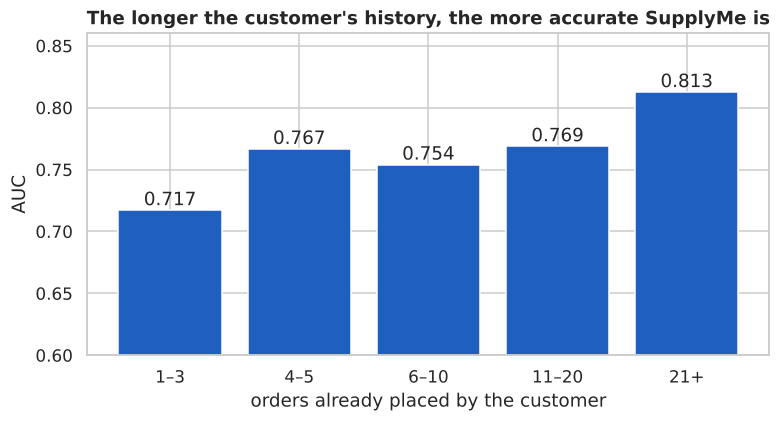

In [25]:
# 2 purchases or more: the main model's accuracy increases with the customer's history
hist_auc = (TE.assign(p=p_final, history=pd.cut(TE["c_orders"], [0, 3, 5, 10, 20, 1000],
                                                labels=["1–3", "4–5", "6–10", "11–20", "21+"]))
            .groupby("history", observed=True)
            .apply(lambda g: pd.Series({"observations": len(g), "AUC": roc_auc_score(g.buy_within_7d, g.p)})))
display(hist_auc.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(hist_auc.index.astype(str), hist_auc.AUC, color=BLUE)
for i, v in enumerate(hist_auc.AUC): ax.text(i, v + 0.004, f"{v:.3f}", ha="center")
ax.set(ylim=(0.6, 0.86), title="The longer the customer's history, the more accurate SupplyMe is",
       xlabel="orders already placed by the customer", ylabel="AUC")
plt.show()

**Interpretation:**

- **0 orders:** the 10 best-sellers recover only **7%** of a customer's 2nd basket, while their own 1st basket recovers **29%**. A single order therefore brings 4 times more information than popularity: with a new customer, the key is to obtain their 1st order **quickly**.
- **1 purchase of a product:** by relying on the experience of other customers, the **cold-start model** reaches an AUC of **0.742**, versus 0.697 for the simple rule. It reduces the error on the delay from **22.2 to 13.9 days** (−37%).
- **2 purchases or more:** the main model's accuracy increases with the customer's history, from 0.717 (1 to 3 orders) to **0.813** (21 orders or more). The more the customer buys, the better SupplyMe knows them.

## 12 ter. New customers with no order: welcome basket, questionnaire and points

For a customer who has not bought anything yet, SupplyMe works in three steps:

1. **Welcome basket:** the products that other customers buy **and reorder** the most (score = number of buyers × reorder rate).
2. **Welcome questionnaire:** the customer states their favourite departments (up to 3), household size, diet and shopping frequency. Each department stated earns **10 points**, plus **50 bonus points** if all 3 departments are filled in (100 points = $1 off the 1st order). This cost is counted.
3. **Personalisation:** the 10 slots of the basket are split between departments in proportion to the **smoothed** preferences (Dirichlet, α = 30, chosen by validation in the group dataset): p_d = (1{d chosen} + α·q_d) / (k + α). With no answer, we fall back on the average customer.

**Evaluation on real data:** the 1,500 "holdout" customers of the group dataset play the role of new customers; we only look at their **real 1st order** and measure the share recovered by the proposed basket (Recall@10). Since questionnaire answers do not exist in Instacart, they are **simulated** for this evaluation from the customer's later purchases (with noise and 15% inaccurate answers), and compared with a **placebo** (another customer's answers).

In [26]:
POINTS_PER_DEPT, FULL_BONUS, POINT_VALUE, ALPHA = 10, 50, 0.01, 30
def points(n): return n * POINTS_PER_DEPT + (FULL_BONUS if n >= 3 else 0)

def welcome_ranking(d_):
    p = d_.groupby("product_id").agg(buyers=("user_id", "nunique"), lines=("order_id", "size"),
                                     reorders=("reordered", "sum"), department=("department", "first"), product=("product_name", "first"))
    p["reorder_rate"] = (p.reorders + 1) / (p.lines + 2)
    p["score"] = p.buyers * p.reorder_rate
    return p.sort_values("score", ascending=False)

def smoothed_preferences(depts, q, alpha=ALPHA):
    c = pd.Series(0.0, index=q.index); c[[r for r in depts if r in c.index]] = 1.0
    return (c + alpha * q) / (len(depts) + alpha)

def personalised_basket(ranking, pref, n=10):
    target = pref.reindex(ranking.department.unique()).fillna(0); target = target / target.sum() * n
    slots = np.floor(target).astype(int); slots[(target - slots).nlargest(n - slots.sum()).index] += 1
    return [pid for dept, k in slots[slots > 0].items() for pid in ranking.index[ranking.department == dept][:k]]

split = pd.read_excel(f"{BASE}/audit/customer_split.xlsx")
holdout = set(split.loc[split.split == "holdout", "user_id"])
known, newcomers = df[~df.user_id.isin(holdout)], df[df.user_id.isin(holdout)]
ranking = welcome_ranking(known)
q = known.department.value_counts() + 0.5; q = q / q.sum()
first_order = newcomers[newcomers.order_number == 1].groupby("user_id").product_id.apply(set)

rng_q = np.random.default_rng(SEED + 4)
later = {u: g.value_counts() for u, g in newcomers[newcomers.order_number > 1].groupby("user_id").department}
answers = {}
for u in first_order.index:
    if u in later:
        v = later[u] * rng_q.lognormal(0, 0.6, len(later[u])); choice = list(v.nlargest(3).index)
        if rng_q.random() < 0.15: choice[-1] = rng_q.choice([r for r in q.index if r not in choice])
        answers[u] = choice
users_q = [u for u in first_order.index if u in answers]
placebo = dict(zip(users_q, [answers[u] for u in rng_q.permutation(users_q)]))
pop10 = list(known.groupby("product_id").user_id.nunique().nlargest(10).index)
recall = lambda recos: np.mean([len(set(recos[u]) & first_order[u]) / len(first_order[u]) for u in users_q]) * 100
eval_welcome = pd.DataFrame({"Recall@10 (%)": {
    "Top 10 most purchased products": recall({u: pop10 for u in users_q}),
    "Welcome basket (bought and rebought)": recall({u: list(ranking.index[:10]) for u in users_q}),
    "Basket split by department, no answers": recall({u: personalised_basket(ranking, q) for u in users_q}),
    "Basket split by department, with questionnaire (simulated)": recall({u: personalised_basket(ranking, smoothed_preferences(answers[u], q)) for u in users_q}),
    "Placebo: another customer's answers": recall({u: personalised_basket(ranking, smoothed_preferences(placebo[u], q)) for u in users_q}),
}})
print(f"New customers evaluated: {len(users_q):,}")
display(eval_welcome.round(2))
print("The welcome basket:")
display(ranking.head(10)[["product", "department", "buyers", "reorder_rate"]].round(3))

New customers evaluated: 1,500


,Recall@10 (%)
Top 10 most purchased products,7.130
Welcome basket (bought and rebought),7.130
"Basket split by department, no answers",5.000
"Basket split by department, with questionnaire (simulated)",5.130
Placebo: another customer's answers,4.940


The welcome basket:


,product,department,buyers,reorder_rate
product_id,,,,
24852,Banana,produce,555,0.841
13176,Bag of Organic Bananas,produce,470,0.849
21137,Organic Strawberries,produce,442,0.758
21903,Organic Baby Spinach,produce,421,0.774
47209,Organic Hass Avocado,produce,313,0.790
16797,Strawberries,produce,333,0.708
47626,Large Lemon,produce,334,0.699
26209,Limes,produce,335,0.687
47766,Organic Avocado,produce,305,0.747


In [27]:
# The group's 1,000 new accounts: answers, points earned and personalised basket
nc = accounts[accounts.origin == "synthetic_new"][["account_id", "onboarding_state"]].copy()
ans_ = pd.read_excel(f"{BASE}/app/onboarding_answers.xlsx").merge(departments, on="department_id")
nc["departments"] = nc.account_id.map(ans_.groupby("account_id").department.apply(list)).apply(lambda v: v if isinstance(v, list) else [])
nc["n_answers"] = nc.departments.str.len()
nc["points"] = nc.n_answers.apply(points)
nc["value ($)"] = nc.points * POINT_VALUE
display(nc.groupby("n_answers").agg(accounts=("account_id", "size"), points=("points", "first"), value=("value ($)", "first")))
print(f"Average cost of points per new account: ${nc['value ($)'].mean():.2f}")

example_nc = nc[nc.n_answers == 3].iloc[0]
print(f"\nExample: account {example_nc.account_id}, departments chosen: {', '.join(example_nc.departments)}")
ranking_all = welcome_ranking(df)
q_all = df.department.value_counts() + 0.5; q_all = q_all / q_all.sum()
display(ranking_all.loc[personalised_basket(ranking_all, smoothed_preferences(example_nc.departments, q_all)), ["product", "department"]])

assoc = pd.read_excel(f"{BASE}/app/product_associations.xlsx")
print("Complementary products (real co-purchases, group dataset), example for the 1st product of the basket:")
p0_ = ranking_all.index[0]
display(assoc[assoc.product_id == p0_].nlargest(5, "lift").assign(complement=lambda d: d.related_product_id.map(cat.set_index("product_id").product_name))
        [["complement", "co_purchases", "confidence", "lift"]].round(3))

,accounts,points,value
n_answers,,,
0,334,0,0.000
1,333,10,0.100
3,333,80,0.800


Average cost of points per new account: $0.30

Example: account N00002, departments chosen: deli, produce, snacks


,product,department
product_id,,
24852,Banana,produce
13176,Bag of Organic Bananas,produce
21137,Organic Strawberries,produce
27845,Organic Whole Milk,dairy eggs
49235,Organic Half & Half,dairy eggs
30489,Original Hummus,deli
9076,Blueberries,frozen
44632,Sparkling Water Grapefruit,beverages
31506,Extra Virgin Olive Oil,pantry


Complementary products (real co-purchases, group dataset), example for the 1st product of the basket:


,complement,co_purchases,confidence,lift
39741,Honeycrisp Apple,406,0.062,2.594
39739,Seedless Red Grapes,417,0.063,2.549
39740,Organic Fuji Apple,415,0.063,2.471
39733,Organic Avocado,683,0.104,2.218
39735,Strawberries,579,0.088,1.973


**Interpretation:**

- **For a very first order, best-sellers remain the best proposal:** they recover 7.1% of the products of the real 1st order. The "bought and rebought" basket does just as well, with products the customer will keep in their habits.
- **The questionnaire brings a small real signal:** with answers, the basket split by department recovers 5.13%, versus 4.94% with another customer's answers (placebo). But splitting the basket between departments costs more than the answers bring: bananas and strawberries are bought by almost everyone.
- **Practical conclusion:** the questionnaire is mainly used to **get to know the customer** (departments, household, diet) and to **start the relationship**. It costs $0.30 of points per new account on average, and $0.80 for a complete questionnaire. The proposed basket stays based on best-sellers, enriched with **complementary products** (real co-purchases: banana → apples, grapes, avocado).
- Since the answers are synthetic in Instacart, this part is a **demonstration of the method**; the 1st order used for the evaluation, however, is real.

## 13. Prediction at today's date

We apply the selected models at the analysis date (31 October 2026): for each customer × usual product pair, we obtain **the likely date of the next purchase** and **the probability of purchase within 7 days**. The models are retrained on all the available data.

In [28]:
all_ = pd.concat([TR, TE], ignore_index=True)
reg_final.fit(all_.loc[~all_.censored, FEATURES], all_.loc[~all_.censored, "days_to_next_purchase"])
clf_final.fit(all_[FEATURES], all_["buy_within_7d"]) if BEST_CLS != "Random Forest" else clf_final.fit(all_.sample(400_000, random_state=SEED)[FEATURES], all_.sample(400_000, random_state=SEED)["buy_within_7d"])

TODAY = 365
P = build_features(TODAY, with_target=False)
P[FEATURES] = P[FEATURES].astype(float).fillna(-1)
P["predicted_delay"] = np.clip(reg_final.predict(P[FEATURES]), 1, H)
P["proba_7d"] = clf_final.predict_proba(P[FEATURES])[:, 1]
P["predicted_date"] = END_DATE + pd.to_timedelta(P["predicted_delay"].round(), unit="D")
P = P.merge(cat_s[["product_id", "product_name", "department", "price", "margin"]], on="product_id", suffixes=("_id", ""))
print(f"Predictions: {len(P):,} customer × product pairs")
display(P.sort_values("proba_7d", ascending=False)[["user_id", "product_name", "days_since_purchase", "mean_interval",
                                                    "predicted_delay", "predicted_date", "proba_7d"]].head(10).round(2))

Predictions: 80,946 customer × product pairs


,user_id,product_name,days_since_purchase,mean_interval,predicted_delay,predicted_date,proba_7d
11786,31606,Total 2% Lowfat Greek Strained Yogurt With Blu...,2.000,3.710,2.630,2026-11-03,0.990
11813,31606,Total 2% with Strawberry Lowfat Greek Strained...,2.000,4.010,2.870,2026-11-03,0.990
76061,192439,Bag of Organic Bananas,11.000,4.790,2.470,2026-11-02,0.970
11814,31606,Total 2% Lowfat Greek Strained Yogurt with Peach,2.000,4.740,3.410,2026-11-03,0.970
55835,142664,Golden Pineapple,2.000,5.510,6.250,2026-11-06,0.960
27437,70309,Banana,0.000,5.570,6.390,2026-11-06,0.960
42391,106580,100% Whole Wheat Bread,5.000,5.400,2.310,2026-11-02,0.960
27422,70309,Gluten and Dairy Free Rice Macaroni and Cheeze,0.000,5.370,6.540,2026-11-07,0.960
3935,10886,Bag of Organic Bananas,4.000,5.770,1.940,2026-11-02,0.950
4913,12899,Bag of Organic Bananas,7.000,5.820,5.130,2026-11-05,0.950


## 14. Part 4: the best time to contact the customer

Instacart provides the real **hour** and **day** of each order. For each customer, we keep their **usual hour** (the most frequent one) and their **usual day**.

**Sending rule:** the message is sent **1 day before the predicted date of need**, **1 hour before the usual ordering hour** (the customer has time to see the message before the moment they usually order).

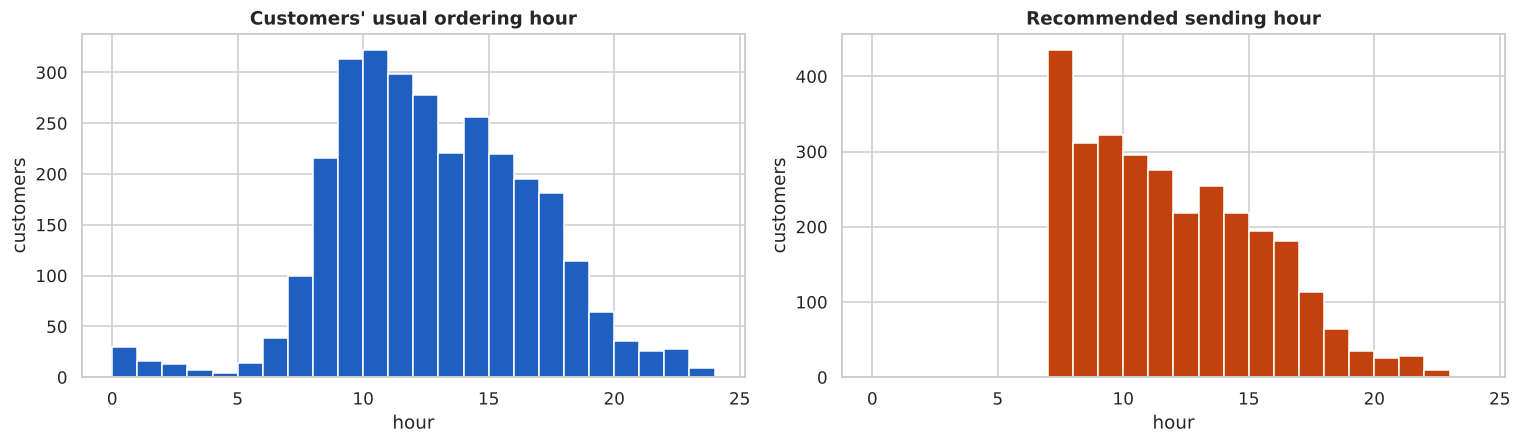

In [29]:
habit = o.groupby("user_id").agg(usual_hour=("order_hour_of_day", lambda s: int(s.mode().iloc[0])),
                                 usual_day=("order_dow", lambda s: int(s.mode().iloc[0])))
P = P.merge(habit, left_on="user_id", right_index=True)
P["send_date"] = (P["predicted_date"] - pd.Timedelta(days=1)).clip(lower=END_DATE + pd.Timedelta(days=1))
P["send_hour"] = (P["usual_hour"] - 1).clip(lower=7)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(habit["usual_hour"], bins=range(0, 25), color=BLUE)
axes[0].set(title="Customers' usual ordering hour", xlabel="hour", ylabel="customers")
axes[1].hist(P.drop_duplicates("user_id")["send_hour"], bins=range(0, 25), color=ORANGE)
axes[1].set(title="Recommended sending hour", xlabel="hour", ylabel="customers")
plt.tight_layout(); plt.show()

## 15. Part 5: assessing whether a discount is worthwhile

### The economic model (**incremental** reasoning)
We only count purchases **caused** by the message. For a product with price *R* and margin *m*:

| Scenario | Purchase probability | Incremental profit |
|---|---|---|
| **A — Simple reminder** | pA = p0 + u·(1 − p0) | (pA − p0)·V − c |
| **B — Reminder + discount d** | pB = min(pA·(1 + 2.62·d), 0.95) | pB·(V − d·R) − p0·V − c |
| **C — No reminder** | p0 | 0 |

**V = value of a purchase won.** Two cases:
- **imminent need** (purchase expected within 7 days, habit intact): V = m, the margin of a single purchase;
- **overdue need** (a real habit, bought at least 3 times at a regular pace, but no purchase for 1.5 to 3 times the usual interval: the customer may have bought elsewhere): winning them back means **recovering the habit** for the next 3 months. V = m × number of purchases expected in 90 days (90 ÷ usual interval, capped at 6). This is the **customer lifetime value** logic: we invest in a discount to save several future purchases, not just one.

- **p0:** probability of purchase without a reminder = **output of the model selected in §12**;
- **2.62:** average price elasticity from the meta-analysis by Bijmolt *et al.* (2005): −10% in price ≈ +26% in demand;
- **u = 5%:** share of hesitant customers convinced by a simple reminder — **assumption**, tested from 0 to 10% in §17;
- **c = $0.05:** cost of a message (delivery + CRM tool) — **assumption**, shared between the products of the same message.

The discount is paid to **all** buyers, including those who would have bought without it: this is the **windfall effect**.

In [30]:
U_REMINDER, ELASTICITY, MSG_COST, DISCOUNTS, P_MAX = 0.05, 2.62, 0.05, [0.05, 0.10, 0.15, 0.20], 0.95

def proba_A(p0, u=U_REMINDER): return np.minimum(p0 + u * (1 - p0), P_MAX)
def proba_B(p0, d, u=U_REMINDER, e=ELASTICITY): return np.minimum(proba_A(p0, u) * (1 + e * d), P_MAX)
LOYALTY_HORIZON = 90   # days of behaviour recovered when a customer is won back (assumption)
def gain_A(p0, V, u=U_REMINDER): return (proba_A(p0, u) - p0) * V
def gain_B(p0, V, R, d, u=U_REMINDER, e=ELASTICITY): return proba_B(p0, d, u, e) * (V - d * R) - p0 * V

# Teaching examples: product at $10, margin 27.9% ($2.79)
examples = [("Loyal customer, imminent need", 0.80, 2.79),
            ("Hesitant customer, imminent need", 0.20, 2.79),
            ("Lapsed customer, weekly product", 0.20, 2.79 * 6)]
for name, p0, V in examples:
    gA = gain_A(p0, V); gB = {d: gain_B(p0, V, 10, d) for d in DISCOUNTS}
    best = max(gB, key=gB.get)
    choice = "B — discount" if gB[best] > gA else "A — reminder"
    print(f"{name:<38} p0={p0:.0%} | reminder: {gA:+.3f} $ | discount -{best:.0%}: {gB[best]:+.3f} $ → {choice}")

Loyal customer, imminent need          p0=80% | reminder: +0.028 $ | discount -5%: -0.134 $ → A — reminder
Hesitant customer, imminent need       p0=20% | reminder: +0.112 $ | discount -5%: +0.064 $ → A — reminder
Lapsed customer, weekly product        p0=20% | reminder: +0.670 $ | discount -20%: +2.043 $ → B — discount


Needs detected: 4,662 products for 1,337 customers


decision,A — reminder,B — discount,C — none,Total
segment,,,,
imminent need,969,0,332,1301
overdue need,4,3291,66,3361
Total,973,3291,398,4662


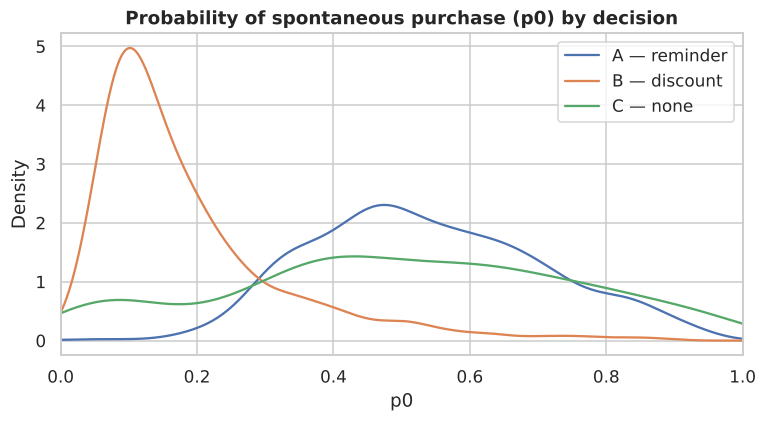

In [31]:
def decide(P, u=U_REMINDER, e=ELASTICITY, c=MSG_COST, window=7):
    habit_ok = (P.n_purchases >= 3) & (P.interval_sd <= P.mean_interval)        # repeated and fairly regular purchase
    overdue = habit_ok & P.overdue_index.between(1.5, 3) & (P.days_since_purchase <= 60)
    imminent = (P.predicted_delay <= window) & ~overdue
    C = P[imminent | overdue].copy()
    C["segment"] = np.where(overdue[imminent | overdue], "overdue need", "imminent need")
    C["value"] = np.where(C.segment == "overdue need",
                          C.margin * np.minimum(LOYALTY_HORIZON / C.mean_interval.clip(lower=1), 6), C.margin)
    p0, V, R = C.proba_7d.values, C.value.values, C.price.values
    C["gain_A"] = gain_A(p0, V, u)
    gB = np.column_stack([gain_B(p0, V, R, d, u, e) for d in DISCOUNTS])
    C["best_discount"] = np.array(DISCOUNTS)[gB.argmax(1)]
    C["gain_B"] = gB.max(1)
    C["option"] = np.where(C.gain_B > C.gain_A, "B — discount", "A — reminder")
    C["gain"] = C[["gain_A", "gain_B"]].max(1)
    # at most 12 products per message: we keep the 12 most profitable ones for each customer ("pool")
    C["pool"] = C["gain"].groupby(C.user_id).rank(ascending=False, method="first") <= 12
    C.loc[(C.gain <= 0) | ~C.pool, "option"] = "C — none"
    useful = C.option != "C — none"
    total = C[useful].groupby("user_id")["gain"].sum()
    send = total[total > c].index
    C["decision"] = np.where(C.user_id.isin(send) & useful, C.option, "C — none")
    n_prod = C[C.decision != "C — none"].groupby("user_id")["product_id"].transform("size")
    C["profit"] = 0.0
    C.loc[C.decision != "C — none", "profit"] = C.loc[C.decision != "C — none", "gain"] - c / n_prod
    C["discount"] = np.where(C.decision == "B — discount", C.best_discount, 0.0)
    # overdue need: we send the reminder tomorrow
    C.loc[C.segment == "overdue need", "send_date"] = END_DATE + pd.Timedelta(days=1)
    return C

C = decide(P)
print(f"Needs detected: {len(C):,} products for {C.user_id.nunique():,} customers")
display(pd.crosstab(C.segment, C.decision, margins=True, margins_name="Total"))
fig, ax = plt.subplots(figsize=(8, 3.8))
C.groupby("decision")["proba_7d"].plot(kind="kde", ax=ax, legend=True)
ax.set(title="Probability of spontaneous purchase (p0) by decision", xlabel="p0", xlim=(0, 1))
plt.show()

## 16. Part 6: the personalised basket

In [32]:
def basket_of(customer):
    b = C[(C.user_id == customer) & (C.decision != "C — none")].sort_values("predicted_date")
    b = b.assign(final_price=(b.price * (1 - b.discount)).round(2))
    return b[["product_name", "department", "segment", "predicted_date", "proba_7d", "decision", "discount", "price", "final_price", "profit"]]

def message(customer):
    b = basket_of(customer)
    h = int(C.loc[C.user_id == customer, "send_hour"].iloc[0]); d = C.loc[C.user_id == customer, "send_date"].min()
    lines = "\n".join(f"  - {r.product_name}: ${r.final_price:.2f}" + (f"  (-{r.discount:.0%})" if r.discount else "") for r in b.itertuples())
    return (f"Scheduled for {d:%m/%d/%Y} at {h}:00\n\nSubject: Your usual basket is ready\n\n"
            f"Hello, based on your habits, you will soon run out of these products:\n{lines}\n\n"
            f"Total: ${b.final_price.sum():.2f}. Confirm in one click.")

contacted = C[C.decision != "C — none"].groupby("user_id").size()
example = contacted[contacted.between(4, 8)].index[0]
print(f"Customer {example}:"); display(basket_of(example).round(3))
print(message(example))

Customer 63:


,product_name,department,segment,predicted_date,proba_7d,decision,discount,price,final_price,profit
18,Apple Honeycrisp Organic,produce,overdue need,2026-11-18,0.189,B — discount,0.200,0.660,0.530,0.115
11,Organic Broccoli Crowns,produce,overdue need,2026-11-19,0.158,B — discount,0.200,1.350,1.080,0.240
67,Organic Plain Whole Milk Yogurt,dairy eggs,overdue need,2026-11-21,0.123,B — discount,0.200,3.770,3.020,0.335
70,Organic Zucchini,produce,overdue need,2026-11-23,0.097,B — discount,0.200,1.450,1.160,0.081


Scheduled for 11/01/2026 at 11:00

Subject: Your usual basket is ready

Hello, based on your habits, you will soon run out of these products:
  - Apple Honeycrisp Organic: $0.53  (-20%)
  - Organic Broccoli Crowns: $1.08  (-20%)
  - Organic Plain Whole Milk Yogurt: $3.02  (-20%)
  - Organic Zucchini: $1.16  (-20%)

Total: $5.79. Confirm in one click.


## 17. Part 7: campaign profitability

We compare SupplyMe with simple strategies, on **exactly the same products** (each customer's 12 most important needs).

,customers contacted,incremental profit ($),discount cost ($),message cost ($)
strategy,,,,
No campaign,0,0.000,0.000,0.000
"Reminder to everyone, no discount",1337,522.680,0.000,66.850
10% discount to everyone,1337,989.930,521.060,66.850
SupplyMe (targeted),1274,"1,537.920",668.430,63.700


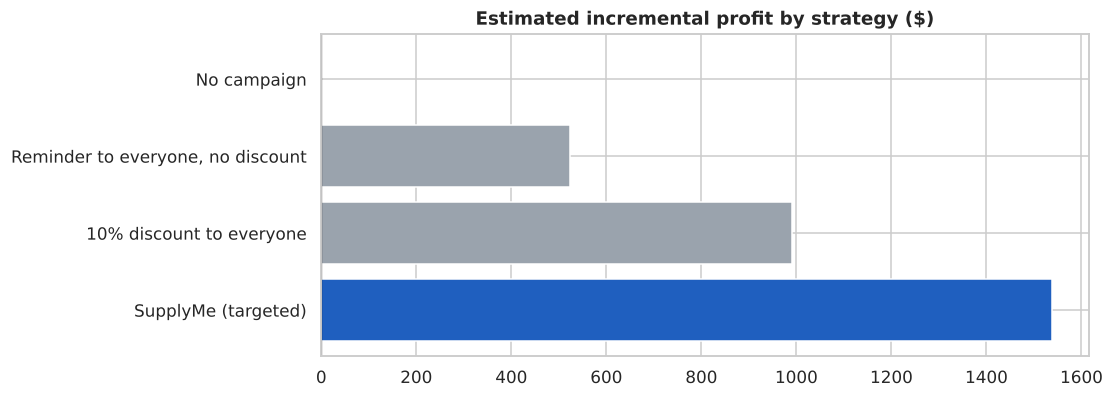

In [33]:
def strategies(C, u=U_REMINDER, e=ELASTICITY, c=MSG_COST):
    C = C[C.pool]                                   # same set of products for every strategy
    p0, m, R = C.proba_7d.values, C.value.values, C.price.values
    n = C.user_id.nunique(); s = C.decision != "C — none"
    rows = [("No campaign", 0, 0.0, 0.0),
            ("Reminder to everyone, no discount", n, gain_A(p0, m, u).sum() - n * c, 0.0),
            ("10% discount to everyone", n, gain_B(p0, m, R, 0.10, u, e).sum() - n * c, (proba_B(p0, 0.10, u, e) * 0.10 * R).sum()),
            ("SupplyMe (targeted)", C.loc[s, "user_id"].nunique(), C.profit.sum(),
             (proba_B(p0[s], C.loc[s, "discount"].values, u, e) * C.loc[s, "discount"].values * R[s]).sum())]
    t = pd.DataFrame(rows, columns=["strategy", "customers contacted", "incremental profit ($)", "discount cost ($)"])
    t["message cost ($)"] = t["customers contacted"] * c
    return t.set_index("strategy")

T = strategies(C)
display(T.round(2))
plt.figure(figsize=(9, 3.8))
plt.barh(T.index[::-1], T["incremental profit ($)"][::-1], color=[BLUE, GREY, GREY, GREY])
plt.axvline(0, color=DARK, lw=0.8); plt.title("Estimated incremental profit by strategy ($)"); plt.show()

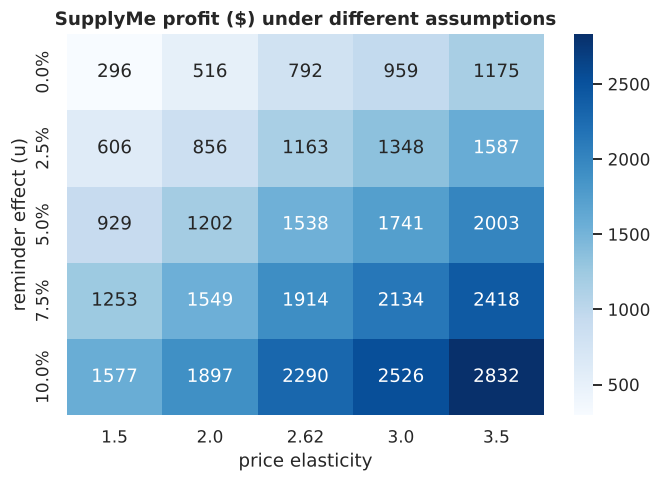

In [34]:
# Sensitivity analysis: does the result hold if our assumptions are wrong?
us, es = [0.0, 0.025, 0.05, 0.075, 0.10], [1.5, 2.0, 2.62, 3.0, 3.5]
sens = pd.DataFrame([[decide(P, u, e).profit.sum() for e in es] for u in us],
                    index=[f"{u:.1%}" for u in us], columns=[f"{e}" for e in es])
plt.figure(figsize=(7, 4.5))
sns.heatmap(sens, annot=True, fmt=".0f", cmap="Blues")
plt.title("SupplyMe profit ($) under different assumptions"); plt.ylabel("reminder effect (u)"); plt.xlabel("price elasticity")
plt.show()

## 18. Conclusion

**What the analysis shows, part by part (group dataset: 3,000 real Instacart customers):**

1. **Purchase histories:** 16 orders and $514 spent on average per household over one year. Larger households have bigger baskets.
2. **Habits:** 47,569 customer × product pairs bought at least 3 times, **80%** of which are regular or very regular.
3. **Prediction:** five approaches compared on a future period never seen during training. The delay is predicted with **31% less error** than the simple rule (LightGBM: 12.1 days versus 17.5). The probability of purchase within 7 days, estimated by the logistic regression selected on the validation period, reaches an **AUC of 0.789** (versus 0.739).
4. **New customers:** welcome basket, questionnaire with loyalty points, then a cold-start model from the 1st purchase onwards (AUC 0.742, error −37%).
5. **Sending time:** 1 day before the need, 1 hour before the usual ordering hour.
6. **Discount:** useless for an imminent need (windfall effect), profitable to win back a habit that is being lost.
7. **Profitability:** SupplyMe brings **$1,538** of incremental profit, versus **$990** for a 10% discount to everyone and **$523** for a reminder to everyone, i.e. **+55%**. The profit stays **positive in every scenario tested** (from $296 to $2,832).

### Acknowledged limitations
- Dates are reconstructed; prices and households are anchored on official sources but **simulated** at the individual level.
- Instacart caps gaps at 30 days: long cycles are underestimated.
- Welcome-questionnaire answers are synthetic (group dataset): the contribution of the questionnaire is a demonstration, not a measurement.
- The reminder effect and the message cost are **assumptions**: only a real **A/B test** could measure them.

### Sources
- U.S. Bureau of Labor Statistics — *Average Price Data*, U.S. city average.
- NGA / FMS Solutions — *Independent Grocers Financial Survey* (2025); FMI — *Industry Speaks* (2021).
- U.S. Energy Information Administration — *RECS 2024*, table HC9.4.
- Bijmolt, T., Van Heerde, H., Pieters, R. (2005). *New Empirical Generalizations on the Determinants of Price Elasticity*. Journal of Marketing Research, 42(2), 141–156.

In [35]:
# Export of the results (for the Streamlit application and the report)
OUT = "supplyme_results"
os.makedirs(OUT, exist_ok=True)
tab_reg.to_csv(f"{OUT}/model_comparison_regression.csv")
tab_cls.to_csv(f"{OUT}/model_comparison_classification.csv")
P.to_csv(f"{OUT}/predictions.csv", index=False)
C.to_csv(f"{OUT}/campaign.csv", index=False)
T.to_csv(f"{OUT}/strategies.csv")
print("Files exported to", OUT, ":", sorted(os.listdir(OUT)))

Files exported to supplyme_results : ['campaign.csv', 'model_comparison_classification.csv', 'model_comparison_regression.csv', 'predictions.csv', 'strategies.csv']
